# Session 7, planetary science track: planets around other stars

Wednesday 14 October 2026, 10:00 to 11:20, alone or with your team. Each question has a self-check that prints `correct` or a hint, never the answer, and a collapsed worked solution for after you have tried.

**Learning outcomes.** After this session you can:

1. Check that a light curve or planet table you downloaded is the provider's file, unchanged.
2. Say what TESS samples at its native resolution and which processing lies between the detector and the flux you analyse.
3. Tell a real extreme planet from a catalog error with a physical bound.
4. Measure how instrument, processing and catalog problems bias a transit depth and a planet radius, and name the damage cleaning cannot undo.
5. Separate what planets do from what telescopes detect, in a correlation and in training labels.
6. Write rules and instructions that let another person, or an AI tool, rerun your chain from the MAST light curve to the transit depth and planet radius, and check whether it did.

**Objectives for today.** You will:

- compare your downloads of the HD 209458 light curve and two planet tables with the course copies;
- read the header, the table, the light curve and the pixels of one transit;
- hunt the problems planted in a synthetic twin;
- compute mass-radius correlations;
- write the chain from raw files to a training table;
- start the two instruction files for an AI tool that you submit on Friday.

**Before you start** (not in the 80 minutes), work in a copy named with your NetID so that `git pull` never conflicts:

    cd mlgeo-book
    git pull
    cp book/Chapter2-DataManipulation/lab_s07_planetary.ipynb book/Chapter2-DataManipulation/lab_s07_planetary_UWNETID.ipynb
    pixi run jupyter lab

Open the copy from that folder; your files go to `s07_my_files/` there. Nothing today touches your HW1 repository (due tonight, 11:59 pm) or the pixi environment.

Parts 4 and 8 are optional: at 10:37 go to Part 5 and at 11:17 to the wrap-up, wherever you are. Part 5 can borrow their time.

Type your NetID in `MY_NETID = ""` in the setup cell before running it: it chooses the problems planted in your twin. To answer, replace `None` and run the cell. Steps without a label from [1.8](../Chapter1-GettingStarted/1.8_ai_in_your_workflow.md) allow an AI tool.

In [1]:
# Setup: run this cell first. It loads this track's two helper modules and checks the course copies.
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

if not Path("lab_s07_planetary_checks.py").exists():
    raise FileNotFoundError(f"this notebook runs in {Path.cwd()}: open it from mlgeo-book/book/Chapter2-DataManipulation")
import lab_s07_planetary_checks as ck
import lab_s07_planetary_synthetic as syn

check = ck.check
MY_NETID = ""          # your UW NetID in quotes, e.g. "jdoe42": it chooses your planted problems in Part 5
if not MY_NETID:
    print("MY_NETID is empty: you get the class twin, whose problems the worked solutions show.")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

prov = ck.provenance()
for name, rec in prov["files"].items():
    ok = ck.fingerprint(ck.SNAP / name) == rec["sha256"]
    print(f"{'OK  ' if ok else 'FAIL'} {name}  ({rec['bytes']:,} bytes)")
print("course copies made on", prov["retrieved_utc"], "UTC")

MY_NETID is empty: you get the class twin, whose problems the worked solutions show.
OK   nea_pscomppars_2026-10-14.csv  (1,488,119 bytes)
OK   nea_toi_2026-10-14.csv  (895,994 bytes)
OK   tess2022244194134-s0056-0000000420814525-0243-s_lc.fits  (2,039,040 bytes)
OK   tess_s0056_tic420814525_pixels_one_transit.nc  (279,579 bytes)
course copies made on 2026-10-14 06:59 UTC


## Part 0. The system and the question (3 min)

🔭 Telescope · 🗂️ Catalog & compiled product · 🪐 Planets & exoplanets · 🪐 Planetary science & astrobiology

A planet crossing its star blocks, for a few hours each orbit, a fraction of the starlight close to $(R_p/R_\star)^2$. A light curve measures the planet's size relative to its star; the star's radius converts it to kilometres.

HD 209458 is a Sun-like star in Pegasus. Its giant planet, found in 1999 from the star's radial velocity, was the first seen to transit ([Charbonneau et al. 2000](https://doi.org/10.1086/312457); [Henry et al. 2000](https://doi.org/10.1086/312458)) and the first with a detected atmosphere: sodium ([Charbonneau et al. 2002](https://doi.org/10.1086/338770)) and escaping hydrogen ([Vidal-Madjar et al. 2003](https://doi.org/10.1038/nature01448)).

NASA's Transiting Exoplanet Survey Satellite, TESS ([Ricker et al. 2015](https://doi.org/10.1117/1.JATIS.1.1.014003)), has four 24° × 24° cameras covering a 24° × 96° strip ([TESS Instrument Handbook](https://archive.stsci.edu/files/live/sites/mast/files/home/missions-and-data/active-missions/tess/_documents/TESS_Instrument_Handbook_v0.1.pdf), section 2.3), and stares at one strip, a "sector", for about four weeks. HD 209458 fell on camera 1 in sector 56, 2 to 30 September 2022.

**Why it matters.** Radius and mass give bulk density, the first clue to composition: iron and rock, water, or hydrogen and helium. How common rocky planets are is inferred from tables that telescopes filled, and telescopes see some planets far more easily than others.

**Guiding question.** How large are the planets around other stars, and which patterns in planet tables come from the planets themselves and which from what telescopes can detect?

HD 209458 b: star at 48.3 pc, 6091 K, 1.19 solar radii; planet radius 15.58 Earth radii = 1.39 Jupiter radii, orbit 3.525 days; found by Radial Velocity at W. M. Keck Observatory in 1999
6445 confirmed planets in the table; 74.2% first found by transits


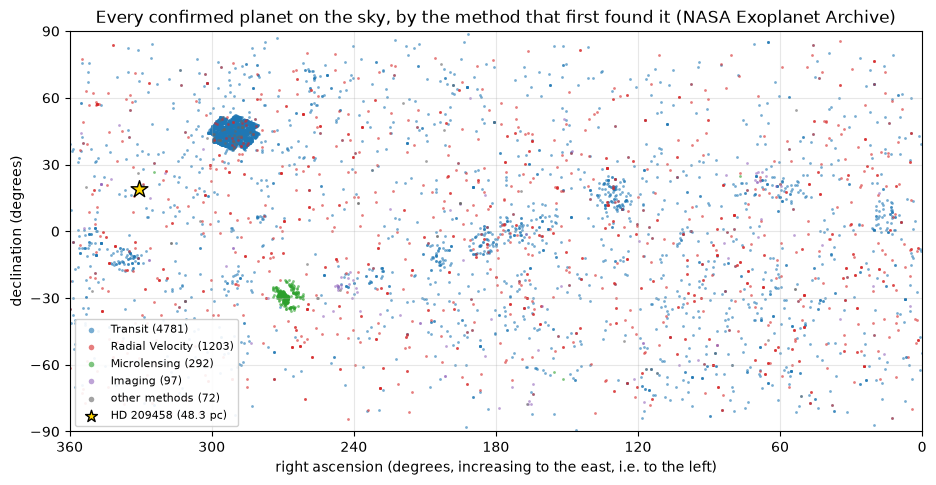

In [2]:
planets = ck.read_planets()
hd = planets.set_index("pl_name").loc[ck.TARGET]
print(f"{ck.TARGET}: star at {hd['sy_dist']:.1f} pc, {hd['st_teff']:.0f} K, {hd['st_rad']:.2f} solar radii; "
      f"planet radius {hd['pl_rade']:.2f} Earth radii = {hd['pl_rade'] / ck.R_JUP_IN_R_EARTH:.2f} Jupiter radii, "
      f"orbit {hd['pl_orbper']:.3f} days; found by {hd['discoverymethod']} at {hd['disc_facility']} in {hd['disc_year']}")
print(f"{len(planets)} confirmed planets in the table; "
      f"{(planets['discoverymethod'] == 'Transit').mean() * 100:.1f}% first found by transits")

fig, ax = plt.subplots(figsize=(11, 5.2))
ck.sky_map(ax, planets)
ax.set_title("Every confirmed planet on the sky, by the method that first found it (NASA Exoplanet Archive)")
plt.show()

**Question 0.** The dense clump near right ascension 290°, declination +45° (Cygnus and Lyra): does it show where planets are in the Milky Way, or where a telescope looked? Answer `"galaxy"` or `"telescope"`, with a reason.

In [3]:
answer_0 = None   # e.g. "telescope: ..." or "galaxy: ..."
check("0", answer_0)

not answered yet


In [4]:
# Worked solution, open after you tried
clump = planets[planets["ra"].between(280, 302) & planets["dec"].between(36, 52)]
print(f"{len(clump)} planets in the clump; who found them:")
print(clump["disc_facility"].value_counts().head(3).to_string())
kep = planets[planets["disc_facility"] == "Kepler"]
print(f"median position of the {len(kep)} Kepler discoveries: RA {kep['ra'].median():.1f}, Dec {kep['dec'].median():.1f}")
# The clump is the one field NASA's Kepler telescope stared at during its main mission: where a telescope looked,
# not where planets live. The band toward RA 270, Dec -29 is the same for microlensing surveys, which point at
# the crowded star fields toward the centre of the Milky Way.

2833 planets in the clump; who found them:
disc_facility
Kepler                    2784
W. M. Keck Observatory      15
Multiple Observatories      10
median position of the 2787 Kepler discoveries: RA 291.3, Dec 44.3


```{admonition} If you are stuck
:class: tip
- *`FileNotFoundError` or `ModuleNotFoundError`:* open the notebook from `book/Chapter2-DataManipulation`, restart the kernel, rerun the setup cell.
- *A line says `FAIL`:* that course copy changed; `git checkout -- book/Chapter2-DataManipulation/snapshots/<file>` restores it.
```

## Part 1. Pull the raw data yourself and know what you have (10 min)

Download (2 min), compare with the course copy (3 min), what a fingerprint catches (2 min), what the telescope measured (3 min).

1. **The planet table**: the Planetary Systems Composite Parameters table of the NASA Exoplanet Archive, one row per confirmed planet, queried in the Astronomical Data Query Language (ADQL), a dialect of SQL.
2. **The TESS Objects of Interest (TOI) table**, same archive: one row per transit-like signal flagged by the TESS team, with its verdict (Part 7).
3. **The light curve** of HD 209458 (TIC 420814525 in the TESS Input Catalog), sector 56: a FITS file (Flexible Image Transport System) from the Mikulski Archive for Space Telescopes (MAST).

Offline, the cell uses the course copies in `snapshots/`.

In [5]:
print("query sent to the archive for the planet table:\n ", ck.PS_QUERY, "\n")
got = ck.fetch_all(timeout=90)
for kind, rec in got.items():
    print(f"{kind:>10}: {rec['source']:<12} {rec['note']}")

query sent to the archive for the planet table:
  select pl_name,hostname,ra,dec,sy_dist,discoverymethod,disc_year,disc_facility,tran_flag,pl_controv_flag,pl_orbper,pl_rade,pl_radeerr1,pl_radelim,pl_bmasse,pl_bmasseerr1,pl_bmasselim,pl_bmassprov,pl_ratror,pl_ratdor,pl_orbincl,pl_trandep,pl_tranmid,st_teff,st_rad from pscomppars order by pl_name 

   planets: course copy  no download (offline mode): the course copy is used
       toi: course copy  no download (offline mode): the course copy is used
lightcurve: course copy  no download (offline mode): the course copy is used


**Is your file the course copy?** Compare the size in bytes, the number of rows, the first and last records, and the **fingerprint**: a SHA-256 code computed from every byte, which changes completely if one byte changes. For the light curve, MAST's copy on Amazon's cloud storage also sends an MD5 fingerprint in a header called `ETag`.

In [6]:
for kind in ["planets", "toi", "lightcurve"]:
    cols = {"course copy": ck.file_facts(ck.course_copy(kind), kind)}
    if got[kind]["source"] == "provider":
        cols["your download"] = ck.file_facts(got[kind]["path"], kind)
    print(f"--- {kind}" + (" (the archive sorts TOI numbers as text: 1000.01 comes before 999.01)"
                           if kind == "toi" else ""))
    display(pd.DataFrame(cols))

same = {k: (ck.fingerprint(got[k]["path"]) == ck.fingerprint(ck.course_copy(k))) if got[k]["source"] == "provider" else None
        for k in got}
ck.remember(same_lightcurve=same["lightcurve"], same_planets=same["planets"])
print("identical bytes:", same)
if got["lightcurve"]["source"] == "provider":
    print("ETag sent by the provider:", got["lightcurve"]["etag"], "| MD5 of your file:", ck.fingerprint(got["lightcurve"]["path"], "md5"))
if got["planets"]["source"] == "provider" and not same["planets"]:
    print(ck.compare_tables(ck.course_copy("planets"), got["planets"]["path"], "pl_name", ["pl_rade", "pl_bmasse", "st_rad"]))

--- planets


,course copy
file,nea_pscomppars_2026-10-14.csv
bytes,1488119
rows,6445
columns,25
first_record,11 Com b
last_record,xi Aql b
sha256,fd1d4fa7b28deeb79e55cbe3ceeae124153b5a0be6a2fc...


--- toi (the archive sorts TOI numbers as text: 1000.01 comes before 999.01)


,course copy
file,nea_toi_2026-10-14.csv
bytes,895994
rows,8148
columns,10
first_record,1000.01
last_record,999.01
sha256,ce1a4803bf80c55530685a4c913fb2b44dd129179dc82a...


--- lightcurve


,course copy
file,tess2022244194134-s0056-0000000420814525-0243-...
bytes,2039040
rows,20079
first_cadence,1150414
last_cadence,1170492
first_time_btjd,2825.257074
last_time_btjd,2853.142587
file_made_on (DATE),2023-09-13
pipeline (PROCVER),spoc-5.0.96-20230729
sha256,1b76b4a4b73e24954fa6e29a7e28a174685113ecdbad1b...


identical bytes: {'planets': None, 'toi': None, 'lightcurve': None}


A difference is not always damage: the archive adds planets and revises values as papers appear, while the light curve, one pipeline release (header `DATA_REL`, `PROCVER`, `DATE`), keeps its bytes until the sector is reprocessed. Read the provider's revision notes before calling a file damaged. The next cell revises one value in memory: the stellar radius of HD 209458 becomes 1.23 instead of 1.19 solar radii.

In [7]:
import hashlib
raw = ck.course_copy("planets").read_bytes()
i = raw.index(b'"HD 209458 b"')
j = raw.index(b"\n", i)
line = raw[i:j]
edited = raw[:i] + line[:line.rindex(b",")] + b",1.230000" + raw[j:]   # st_rad is the last column
for label, b in [("course copy", raw), ("one value revised", edited)]:
    n_rows = len(b.splitlines()) - 1
    print(f"{label:>18}: {len(b):>9,} bytes, {n_rows} rows, sha256 {hashlib.sha256(b).hexdigest()[:24]}...")

       course copy: 1,488,119 bytes, 6445 rows, sha256 fd1d4fa7b28deeb79e55cbe3...
 one value revised: 1,488,119 bytes, 6445 rows, sha256 8d00b4da1a29296bc373784f...


**Question 1a.** Did your downloads have the same bytes as the course copies? (Without a download any answer passes.)

**Question 1b.** After such a revision, which change: the file size, the number of rows, the fingerprint?

In [8]:
answer_1a = {"lightcurve_identical": None, "planets_identical": None}   # True or False
check("1a", answer_1a)
answer_1b = {"size": None, "rows": None, "fingerprint": None}           # True if it changes
check("1b", answer_1b)

not answered yet
not answered yet


In [9]:
# Worked solution, open after you tried
# Download cell tested on 2026-10-14 at 07:15 UTC (all three files in 9 s):
#  - the light curve was identical: same SHA-256 as the course copy, and its MD5 equal to the ETag.
#  - both archive tables were identical too, 16 minutes after the course copies were made. Two downloads of the
#    planet table made seven minutes apart earlier that morning had the same size and different fingerprints;
#    the first was not kept, so which values changed is unknown. A week later, expect new planets and revised values.
# 1b: a revised number with the same number of characters keeps the size and the row count; only the
# fingerprint catches it.
print({"size": False, "rows": False, "fingerprint": True})

{'size': False, 'rows': False, 'fingerprint': True}


**What did the telescope measure?** From the header and the TESS documents quoted in `prov`:

- **Detector.** Four 2048 × 2048 charge-coupled devices (CCDs) per camera. A 15 µm pixel behind a 146 mm lens covers about 21 arcseconds, so a star falls on several pixels.
- **Exposure.** 2-second frames (1.98 s of light, 0.02 s readout) summed on board into one value every 2 minutes. In each block of 10 frames, the highest and lowest value of each pixel are dropped to remove cosmic rays (Instrument Handbook, section 5.1).
- **Ground processing** by the Science Processing Operations Center (SPOC) pipeline: counts (ADU, analog-to-digital units) calibrated to electrons per second, sky background subtracted, aperture pixels summed into `SAP_FLUX` (simple aperture photometry). Presearch Data Conditioning (PDC) then removes trends shared by stars on the same CCD (`PDCMETHD = msMAP`, a multi-scale maximum a posteriori fit), subtracts the neighbours' light (`CROWDSAP` is the target's share) and divides by the share of the star's light inside the aperture (`FLFRCSAP`): `PDCSAP_FLUX`.
- **Clock.** `TIME` is in BTJD (Barycentric TESS Julian Date) = BJD (Barycentric Julian Date) − 2457000 days: the time the light would reach the Solar System's centre of mass, in Barycentric Dynamical Time (TDB). `TIMECORR` is the light-travel correction added to the arrival time at the spacecraft (Science Data Products Description Document, SDPDD).

In [10]:
lc, head = ck.read_lightcurve()
h0, h1 = head["primary"], head["lightcurve"]
for k in ["OBJECT", "SECTOR", "CAMERA", "CCD", "DATA_REL", "PROCVER", "DATE", "CRMITEN", "CRBLKSZ"]:
    print(f"{k:>9} = {h0[k]}")
for k in ["TIMEREF", "TIMESYS", "TIMEDEL", "INT_TIME", "FRAMETIM", "NUM_FRM", "DEADC", "PDCMETHD", "CROWDSAP", "FLFRCSAP"]:
    print(f"{k:>9} = {h1[k]!s:<22} / {head['lightcurve_comments'][k]}")
print(f"pixels in the optimal aperture: {int(((head['aperture'] & 2) > 0).sum())}")
print(f"pixel scale: 15e-6 m / 0.146 m = {15e-6 / 0.146 * 206265:.1f} arcsec")
tc = lc.loc[lc["TIME"].notna(), "TIMECORR"] * 86400
print(f"light-travel correction (TIMECORR, rows with a time): {tc.min():.0f} to {tc.max():.0f} s")
print("SDPDD:", prov["sdpdd"]["quotes"][0])
print(f"median PDCSAP / median SAP = {lc['PDCSAP_FLUX'].median() / lc['SAP_FLUX'].median():.4f};  CROWDSAP / FLFRCSAP = {h1['CROWDSAP'] / h1['FLFRCSAP']:.4f}")

   OBJECT = TIC 420814525
   SECTOR = 56
   CAMERA = 1
      CCD = 2
 DATA_REL = 98
  PROCVER = spoc-5.0.96-20230729
     DATE = 2023-09-13
  CRMITEN = True
  CRBLKSZ = 10
  TIMEREF = SOLARSYSTEM            / barycentric correction applied to times
  TIMESYS = TDB                    / time system is Barycentric Dynamical Time (TDB)
  TIMEDEL = 0.001388888888888889   / [d] time resolution of data
 INT_TIME = 1.98                   / [s] photon accumulation time per frame
 FRAMETIM = 2.0                    / [s] frame time (INT_TIME + READTIME)
  NUM_FRM = 60                     / number of frames per time stamp
    DEADC = 0.792                  / deadtime correction
 PDCMETHD = msMAP                  / PDC algorithm used for target
 CROWDSAP = 0.99778908             / Ratio of target flux to total flux in op. ap.
 FLFRCSAP = 0.95060998             / Frac. of target flux w/in the op. aperture
pixels in the optimal aperture: 23
pixel scale: 15e-6 m / 0.146 m = 21.2 arcsec
light-travel co

**Question 1c.** How many seconds of light go into one 2-minute value of `SAP_FLUX`? Use the header.

**Question 1d.** Which flux column is the least processed, and is this file raw data or a derived product?

In [11]:
answer_1c = None    # seconds, a number
check("1c", answer_1c)
answer_1d = {"least_processed_column": None, "file_is_raw": None}   # a column name; True or False
check("1d", answer_1d)

not answered yet
not answered yet


In [12]:
# Worked solution, open after you tried
print("1c:", h1["TIMEDEL"] * 86400, "s between values x DEADC", h1["DEADC"], "=", h1["TIMEDEL"] * 86400 * h1["DEADC"], "s")
print("   check: 60 frames x 1.98 s x (10 - 2)/10 =", 60 * 1.98 * 8 / 10, "s. The cosmic-ray step costs 20% of the light.")
# 1d: SAP_FLUX is the least processed flux here, but it is already calibrated, background-subtracted and summed
# over 23 pixels and 60 frames: the file is a derived product. Closest to what the CCD recorded is RAW_CNTS in
# the target pixel file (Part 4), itself a 2-minute on-board sum.
# PDC removes the neighbours' share (1 - CROWDSAP) of the median flux, then divides by FLFRCSAP: the medians differ
# by CROWDSAP/FLFRCSAP = 1.0496, and the relative depth grows by 1/CROWDSAP = 1.0022 (0.2%), because subtracting a
# constant deepens a relative dip. A processing step changed the derived quantity. Per transit:
P_, T0_ = hd["pl_orbper"], hd["pl_tranmid"] - 2457000
D_ = syn.transit_duration(P_, hd["pl_ratror"], hd["pl_ratdor"], hd["pl_orbincl"])
ratios = []
for tc_ in T0_ + P_ * np.arange(np.ceil((lc["TIME"].min() - T0_) / P_), np.floor((lc["TIME"].max() - T0_) / P_) + 1):
    w_ = (lc["TIME"] - tc_).abs() < 2 * D_
    d_sap = syn.transit_depth(lc.loc[w_, "TIME"], lc.loc[w_, "SAP_FLUX"], P_, tc_, D_)["depth_ppm"]
    d_pdc = syn.transit_depth(lc.loc[w_, "TIME"], lc.loc[w_, "PDCSAP_FLUX"], P_, tc_, D_)["depth_ppm"]
    ratios.append(d_pdc / d_sap)
print(f"PDCSAP depth / SAP depth, per transit: median {np.median(ratios):.4f} over {len(ratios)} transits; "
      f"1/CROWDSAP = {1 / h1['CROWDSAP']:.4f}")

1c: 120.0 s between values x DEADC 0.792 = 95.04 s
   check: 60 frames x 1.98 s x (10 - 2)/10 = 95.03999999999999 s. The cosmic-ray step costs 20% of the light.
PDCSAP depth / SAP depth, per transit: median 1.0018 over 8 transits; 1/CROWDSAP = 1.0022


```{admonition} If you are stuck
:class: tip
- *The download waits a long time:* each request stops after 90 s and falls back on the course copy; on a slow network use `ck.fetch_all(timeout=20)`.
- *`display` is not defined:* you are outside Jupyter; use `print`.
```

## Part 2. A table: the planet table (8 min)

What a row means (1 min), units (2 min), missing values and flags (2 min), bounds (1 min), one real extreme and one error (2 min). The archive's own description:

In [13]:
import re
plain = lambda s: re.sub(r"\$([^$]*)\$", lambda m: m.group(1).replace("\\", "").replace("_", "").replace("{", "").replace("}", ""), s)   # drop LaTeX marks
print(plain(prov["quotes"]["composite_table"]), "\n")
print(plain(prov["quotes"]["radius_from_mass"]), "(Chen & Kipping 2017, doi:10.3847/1538-4357/834/1/17).")
planets[["pl_name", "discoverymethod", "tran_flag", "pl_orbper", "pl_rade", "pl_bmasse", "pl_bmassprov", "pl_bmasselim", "st_rad"]].head()

By contrast, the goal of the PSCompPars table is to provide users with a table that is as complete as possible with a single row of data per planet. This indicates the PSCompPars table will necessarily include parameters from a variety of references for a given planet, indicating the set of reported parameter values may not be internally or physically self-consistent. 

For planets that do have an empirically determined value for the planet mass Mp but do not have an empirically determined value for the planet radius Rp, regardless of whether the planet has an empirically determined planet density rhop, we invoke the mass-radius relation of Chen & Kipping (2017) to derive the planet radius (Chen & Kipping 2017, doi:10.3847/1538-4357/834/1/17).


,pl_name,discoverymethod,tran_flag,pl_orbper,pl_rade,pl_bmasse,pl_bmassprov,pl_bmasselim,st_rad
0,11 Com b,Radial Velocity,0,323.21000,12.2,4914.898486,Msini,0.0,13.76
1,11 UMi b,Radial Velocity,0,516.21997,12.3,4684.814200,Msini,0.0,29.79
2,14 And b,Radial Velocity,0,186.76000,13.1,1131.151301,Msini,0.0,11.55
3,14 Her b,Radial Velocity,0,1766.41000,12.5,2828.672822,Mass,0.0,0.93
4,16 Cyg B b,Radial Velocity,0,798.50000,13.5,565.737400,Msini,0.0,1.13


**Question 2a.** What does one row record? (a) one measurement of a planet from one paper; (b) one planet, with values from different papers and from the archive's own calculations; (c) one star with all its planets.

**Question 2b.** In which unit is `pl_rade` stored, and the transit depth `pl_trandep` in this table and in the TOI table? See `prov["column_definitions"]`.

In [14]:
answer_2a = None    # "a", "b" or "c"
check("2a", answer_2a)
answer_2b = {"pl_rade": None, "pl_trandep_planets": None, "pl_trandep_toi": None}   # unit names as text
check("2b", answer_2b)

not answered yet
not answered yet


In [15]:
# Worked solution, open after you tried
for t, c in [("pscomppars", "pl_rade"), ("pscomppars", "pl_trandep"), ("toi", "pl_trandep")]:
    print(t, c, "->", prov["column_definitions"][t][c]["label"])
toi = ck.read_toi()
print("HD 209458 b transit depth: planet table", hd["pl_trandep"], "| TOI table", toi.loc[toi["tid"] == ck.TARGET_TIC, "pl_trandep"].iloc[0])
# 2a is (b): one planet per row, values stitched from several references. 2b: Earth radii; percent; parts per
# million (ppm). The same column name holds 1.5 in one table and 17803 in the other, for the same planet.

pscomppars pl_rade -> Planet Radius [Earth Radius]
pscomppars pl_trandep -> Transit Depth [%]
toi pl_trandep -> Planet Transit Depth [ppm]
HD 209458 b transit depth: planet table 1.5 | TOI table 17803.0


**Question 2c.** Count the planets with no mass, with no radius, with a mass computed from the radius (compare the categories of `pl_bmassprov` with its definition), and with a mass that is a limit (`pl_bmasselim` is 1 or −1; the archive does not define these values, so read them as bounds).

In [16]:
# Your exploration here, e.g. planets["pl_bmassprov"].value_counts(dropna=False)

answer_2c = {"no_mass": None, "no_radius": None, "mass_from_radius": None, "mass_is_a_limit": None}   # integers
check("2c", answer_2c)

not answered yet


In [17]:
# Worked solution, open after you tried
print({"no_mass": int(planets["pl_bmasse"].isna().sum()), "no_radius": int(planets["pl_rade"].isna().sum()),
       "mass_from_radius": int((planets["pl_bmassprov"] == "M-R relationship").sum()),
       "mass_is_a_limit": int((planets["pl_bmasselim"].fillna(0) != 0).sum())})
print(planets["pl_bmassprov"].value_counts(dropna=False).to_string())
print("planets that do not transit but have a radius:", int(planets.loc[planets["tran_flag"] == 0, "pl_rade"].notna().sum()))
# Almost half the masses are not measurements: the archive computed them from the radius. The definition of
# pl_bmassprov lists only Mass, M*sin(i)/sin(i) and M*sini; "M-R relationship" is explained on another page.
# For a planet that does not transit (tran_flag = 0), nothing measured the radius: it is usually computed from the mass.

{'no_mass': 31, 'no_radius': 50, 'mass_from_radius': 3032, 'mass_is_a_limit': 239}
pl_bmassprov
M-R relationship    3032
Mass                2472
Msini                926
Msin(i)/sin(i)        15
planets that do not transit but have a radius: 1585


```{admonition} 🔒 By hand
:class: attention
No AI tool for the judgment in this step: state what you expect before you run anything, decide with a physical reason, and read the result against your expectation ([1.8](../Chapter1-GettingStarted/1.8_ai_in_your_workflow.md)).
```

**Question 2d.** Before looking, write physical bounds for a planet's radius (Earth radii) and mass (Earth masses). Jupiter is 11.2 Earth radii and 318 Earth masses (International Astronomical Union (IAU) 2015 nominal values, [Prša et al. 2016](https://doi.org/10.3847/0004-6256/152/2/41)); the archive's upper limit is in `prov["quotes"]["planet_criteria"]`.

In [18]:
answer_2d = {"pl_rade_low": None, "pl_rade_high": None, "pl_bmasse_high": None}
check("2d", answer_2d)
if None not in answer_2d.values():
    out = planets[(planets["pl_rade"] < answer_2d["pl_rade_low"]) | (planets["pl_rade"] > answer_2d["pl_rade_high"])
                  | (planets["pl_bmasse"] > answer_2d["pl_bmasse_high"])]
    print(len(out), "rows outside your bounds")
    display(out[["pl_name", "discoverymethod", "tran_flag", "pl_rade", "pl_bmasse", "pl_bmassprov"]].head(10))

not answered yet


In [19]:
# Worked solution, open after you tried
mine = {"pl_rade_low": 0.3, "pl_rade_high": 25, "pl_bmasse_high": 30 * 317.83}
out = planets[(planets["pl_rade"] < mine["pl_rade_low"]) | (planets["pl_rade"] > mine["pl_rade_high"])]
print(mine)
print(out[["pl_name", "discoverymethod", "pl_rade", "pl_bmasse"]].to_string())
# Above 25 Earth radii: mostly young planets found by direct imaging, whose radii come from models of hot,
# contracting objects, and two transiting planets without a mass (Kepler-1979 b, Kepler-297 d, 2.6 and 2.9
# Jupiter radii) whose source papers deserve a look. No mass exceeds the archive's 30 Jupiter-mass limit.

{'pl_rade_low': 0.3, 'pl_rade_high': 25, 'pl_bmasse_high': 9534.9}
            pl_name discoverymethod   pl_rade   pl_bmasse
142        DH Tau b         Imaging  30.26430  3496.00000
361        GQ Lup b         Imaging  33.60000  6356.00000
526     HD 100546 b         Imaging  77.34210  2701.54146
3495  Kepler-1979 b         Transit  29.33000         NaN
3822   Kepler-297 d         Transit  32.60000         NaN
6176    V2376 Ori b         Imaging  87.20587  6356.56814


**Question 2e. One real extreme, one error.** Compute the bulk density of `Kepler-37 e` and `Kepler-51 b` with `ck.bulk_density(mass, radius)` (Earth 5.5 g/cm³, water 1 g/cm³). One is a real, extreme planet; the other row cannot describe a real body. Which is which?

In [20]:
# Your computation here.

answer_2e = {"error": None, "real_extreme": None}   # planet names, as in the table
check("2e", answer_2e)

not answered yet


In [21]:
# Worked solution, open after you tried
two = planets.set_index("pl_name").loc[["Kepler-37 e", "Kepler-51 b"], ["pl_rade", "pl_bmasse", "pl_bmassprov", "pl_bmasselim", "tran_flag"]]
two["density_g_cm3"] = ck.bulk_density(two["pl_bmasse"], two["pl_rade"])
print(two.to_string())
cmf04 = ck.EARTH_DENSITY * 8 / ((1.07 - 0.21 * 0.4) * 8 ** (1 / 3.7)) ** 3
print(f"Earth-like rock and iron (core mass fraction 0.4) at 8 Earth masses: {cmf04:.1f} g/cm3 "
      "(Zeng et al. 2016 relation, doi:10.3847/0004-637X/819/2/127)")
# Kepler-37 e: 0.37 Earth radii with 8.1 Earth masses is about 880 g/cm3, a hundred times what rock and iron
# reach. The row joins a radius and a minimum mass (Msini) that cannot belong to one body. Error.
# Kepler-51 b: 0.03 g/cm3 is real, a young "super-puff" with a huge hydrogen envelope; its mass comes from transit
# timing (Masuda 2014, doi:10.1088/0004-637X/783/1/53) and Hubble saw a flat transmission spectrum (Libby-Roberts
# et al. 2020, doi:10.3847/1538-3881/ab5d36). A rule like "drop the 1% lowest densities" would delete it.

             pl_rade  pl_bmasse pl_bmassprov  pl_bmasselim  tran_flag  density_g_cm3
pl_name                                                                             
Kepler-37 e     0.37        8.1        Msini           0.0          1     881.752315
Kepler-51 b     7.10        2.1         Mass           0.0          1       0.032353
Earth-like rock and iron (core mass fraction 0.4) at 8 Earth masses: 8.5 g/cm3 (Zeng et al. 2016 relation, doi:10.3847/0004-637X/819/2/127)


```{admonition} If you are stuck
:class: tip
- *`KeyError` on a planet name:* spell it as in the table, or search with `planets[planets['pl_name'].str.contains('Kepler-51')]`.
- *2c is off by a few:* empty cells are `NaN`, not 0: use `.isna().sum()`, and `.fillna(0) != 0` for the limit flag.
```

## Part 3. A 1D array: the light curve (8 min)

Sampling and gaps (3 min), the whole sector in one plot (2 min), one real problem (3 min). One value every 2 minutes for 28 days, varying with the transits every 3.5 days, photon noise, a star quiet at this precision, and what the spacecraft does to the measurement: pointing, temperature, scattered light.

In [22]:
lc[["TIME", "TIMECORR", "CADENCENO", "SAP_FLUX", "SAP_BKG", "PDCSAP_FLUX", "QUALITY"]].describe().T

,count,mean,std,min,25%,50%,75%,max
TIME,19630.0,2.839209e+03,8.094927,2.825257e+03,2.832281e+03,2.839306e+03,2.846327e+03,2.853143e+03
TIMECORR,20079.0,4.755829e-03,0.000740,0.000000e+00,4.708562e-03,4.909222e-03,5.017210e-03,5.069411e-03
CADENCENO,20079.0,1.160453e+06,5796.452363,1.150414e+06,1.155434e+06,1.160453e+06,1.165472e+06,1.170492e+06
SAP_FLUX,19614.0,2.143377e+05,562.882568,2.106415e+05,2.143528e+05,2.144282e+05,2.145092e+05,2.149139e+05
SAP_BKG,19614.0,3.201089e+03,1467.060913,2.458082e+03,2.537906e+03,2.775369e+03,3.186059e+03,1.463309e+04
PDCSAP_FLUX,18792.0,2.249718e+05,595.319275,2.212392e+05,2.250202e+05,2.250774e+05,2.251338e+05,2.255045e+05
QUALITY,20079.0,1.338471e+03,6485.431330,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,3.276800e+04


**Question 3a.** What is the sampling interval in seconds (`np.diff(lc["TIME"])`)? Why is it not exactly 120 s?

**Question 3b.** How many separate blocks of rows have no `TIME` (NaN), and how many hours have `SAP_FLUX` but no `PDCSAP_FLUX`? Quality bits: `prov["quality_bits_sdpdd_table32"]`.

In [23]:
# Your exploration here, e.g. (lc["QUALITY"] & 8 > 0).sum()

answer_3a = None    # seconds
check("3a", answer_3a)
answer_3b = {"blocks_without_time": None, "hours_with_sap_but_no_pdcsap": None}
check("3b", answer_3b)

not answered yet
not answered yet


In [24]:
# Worked solution, open after you tried
dt = np.diff(lc["TIME"]) * 86400
print(f"3a: median {np.nanmedian(dt):.4f} s, range {np.nanmin(dt):.4f} to {np.nanmax(dt[dt < 200]):.4f} s within the stretches")
# The spacecraft samples every 120 s by its own clock; TIME is barycentric, and the light-travel correction drifts
# as the spacecraft moves around the Sun, so barycentric steps differ from 120 s by milliseconds.
nt = lc["TIME"].isna().to_numpy()
blocks = np.flatnonzero(np.diff(np.r_[0, nt.astype(int)]) == 1)
print("3b: blocks without time:", len(blocks), "| rows:", nt.sum(), "| quality of those rows:", lc.loc[nt, "QUALITY"].value_counts().to_dict())
gap = lc["PDCSAP_FLUX"].isna() & lc["SAP_FLUX"].notna()
print("    hours with SAP but no PDCSAP:", gap.sum() * 2 / 60, "| quality there:", lc.loc[gap, "QUALITY"].value_counts().to_dict())
for b, txt in prov["quality_bits_sdpdd_table32"].items():
    if int(b) in (8, 32, 32768):
        print(f"    bit value {b}: {txt}")

3a: median 119.9978 s, range 119.9956 to 120.0001 s within the stretches
3b: blocks without time: 3 | rows: 449 | quality of those rows: {8: 449}
    hours with SAP but no PDCSAP: 27.4 | quality there: {32768: 820, 128: 2}
    bit value 8: Spacecraft is in Earth Point
    bit value 32: Reaction Wheel desaturation Event
    bit value 32768: Insufficient Targets for Error Correction Exclude (spoc-4.0.14 and later).


Both fluxes divided by their median, and the background the pipeline subtracted:

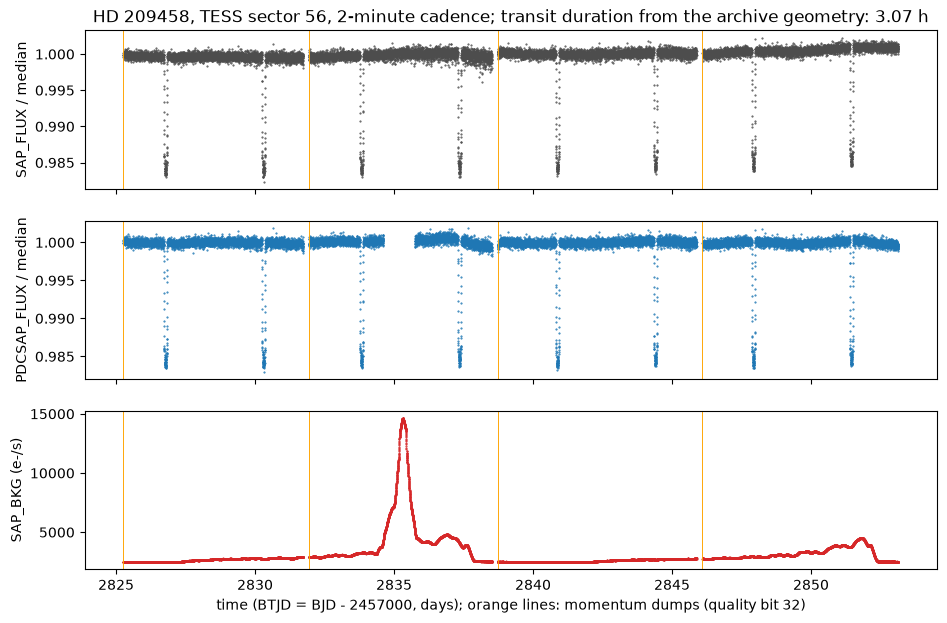

In [25]:
P, T0 = hd["pl_orbper"], hd["pl_tranmid"] - 2457000
D = syn.transit_duration(P, hd["pl_ratror"], hd["pl_ratdor"], hd["pl_orbincl"])
fig, axs = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
axs[0].plot(lc["TIME"], lc["SAP_FLUX"] / lc["SAP_FLUX"].median(), ".", ms=1, color="0.3")
axs[0].set_ylabel("SAP_FLUX / median")
axs[1].plot(lc["TIME"], lc["PDCSAP_FLUX"] / lc["PDCSAP_FLUX"].median(), ".", ms=1, color="#1f77b4")
axs[1].set_ylabel("PDCSAP_FLUX / median")
axs[2].plot(lc["TIME"], lc["SAP_BKG"], ".", ms=1, color="#d62728")
axs[2].set_ylabel("SAP_BKG (e-/s)")
dumps = lc.loc[(lc["QUALITY"] & 32) > 0, "TIME"]
for ax in axs:
    for t in dumps.dropna():
        ax.axvline(t, color="orange", lw=0.6, alpha=0.6)
axs[2].set_xlabel("time (BTJD = BJD - 2457000, days); orange lines: momentum dumps (quality bit 32)")
axs[0].set_title(f"HD 209458, TESS sector 56, 2-minute cadence; transit duration from the archive geometry: {D * 24:.2f} h")
plt.show()

**Question 3c.** How many transits of HD 209458 b fall inside this sector?

**Question 3d. One real sensor problem.** When (BTJD) is the background highest, and what causes it? The quality bits and handbook quotes in `prov` name the candidate.

In [26]:
answer_3c = None   # an integer
check("3c", answer_3c)
answer_3d = {"time_of_max_background_btjd": None, "cause": None}
check("3d", answer_3d)

not answered yet
not answered yet


In [27]:
# Worked solution, open after you tried
t = lc["TIME"].dropna()
n = np.arange(np.ceil((t.min() - T0) / P), np.floor((t.max() - T0) / P) + 1)
print("3c:", len(n), "transits, mid-times (BTJD):", np.round(T0 + n * P, 3))
i = lc["SAP_BKG"].idxmax()
print(f"3d: background peaks at BTJD {lc.loc[i, 'TIME']:.2f} with {lc.loc[i, 'SAP_BKG']:.0f} e-/s, against a median of {lc['SAP_BKG'].median():.0f} e-/s")
print("   ", prov["instrument_handbook"]["quotes"][3])
# 6-hour means outside transits: how much of the scattered light did the background subtraction leave in SAP_FLUX?
oot_ = (np.abs(ck.phase_days(lc["TIME"], P, T0)) > D) & lc["SAP_FLUX"].notna()
six = lc[oot_].assign(b=(lc.loc[oot_, "TIME"] * 4).round() / 4).groupby("b").agg(bkg=("SAP_BKG", "mean"), sap=("SAP_FLUX", "mean"))
six["sap_ppm"] = (six["sap"] / lc.loc[oot_, "SAP_FLUX"].median() - 1) * 1e6
print(six.loc[2834.5:2836.0].round(0).to_string())
print("rows with the predicted-straylight flag (bit value 2048):", int(((lc["QUALITY"] & 2048) > 0).sum()))
print("a second real problem, a step across the downlink:", six.loc[[2838.5, 2838.75], "sap_ppm"].round(0).to_dict(), "ppm")
# Earth or Moon light scattered into the camera. The background rises to several times its usual level and falls
# within a day, while SAP_FLUX rises by a few hundred ppm: the background subtraction removed almost all of it.
# The stray-light flag (bit value 2048) is never set, although the event is real: the flag is predicted from
# geometry and missed this event. PDC left the 27 hours around the peak empty (bit 32768: too few stars to correct those
# cadences), a hole that the less processed SAP_FLUX does not have. No transit falls in it this time; a search
# run on PDCSAP_FLUX alone would never see one that did. SAP_FLUX also steps by about 800 ppm across the data
# downlink and momentum dump at BTJD 2838.6.

3c: 8 transits, mid-times (BTJD): [2826.78  2830.305 2833.829 2837.354 2840.879 2844.404 2847.928 2851.453]
3d: background peaks at BTJD 2835.32 with 14633 e-/s, against a median of 2775 e-/s
    Each camera is equipped with a lens hood to minimize the levels of stray light from the Earth or Moon striking the detectors.


             bkg       sap  sap_ppm
b                                  
2834.50   3705.0  214402.0   -147.0
2834.75   5708.0  214408.0   -117.0
2835.00   7755.0  214427.0    -30.0
2835.25  13318.0  214451.0     83.0
2835.50  10539.0  214459.0    121.0
2835.75   5374.0  214444.0     51.0
2836.00   4238.0  214445.0     54.0
rows with the predicted-straylight flag (bit value 2048): 0
a second real problem, a step across the downlink: {2838.5: -607.0, 2838.75: 213.0} ppm


```{admonition} If you are stuck
:class: tip
- *Your plot is empty or flat:* divide each column by its own `.median()`, and check that you did not overwrite `lc`.
- *3b is off:* count runs of consecutive NaN, not rows: `np.diff(np.r_[0, lc['TIME'].isna().astype(int)]) == 1` marks the first row of each run.
```

## Part 4. A 2D array: the pixels behind the light curve (8 min, *if you have time*)

Axes (2 min), the star (3 min), where the transit happens (3 min). The light curve sums 23 pixels; the course copy keeps the 13 × 11 pixel stamp around HD 209458 for 0.6 days around one transit (432 cadences), cut from the 58 MB target pixel file. Each image is a 2D array of CCD rows and columns, in electrons per second (`flux`) or raw counts (`raw_cnts`).

In [28]:
px = ck.read_pixels()
print(px)

<xarray.Dataset> Size: 749kB
Dimensions:    (time: 432, row: 13, column: 11)
Coordinates:
  * time       (time) float64 3kB 2.841e+03 2.841e+03 ... 2.841e+03 2.841e+03
  * row        (row) int32 52B 352 353 354 355 356 357 ... 360 361 362 363 364
  * column     (column) int32 44B 1862 1863 1864 1865 ... 1869 1870 1871 1872
Data variables:
    cadenceno  (time) int32 2kB 1161446 1161447 1161448 ... 1161876 1161877
    quality    (time) int32 2kB 0 0 0 0 0 0 0 0 0 0 0 ... 0 0 0 0 0 0 0 0 0 0 0
    raw_cnts   (time, row, column) int32 247kB 212695 212527 ... 212142 211821
    flux       (time, row, column) float32 247kB 63.5 53.91 ... 33.33 14.32
    flux_bkg   (time, row, column) float32 247kB 108.9 108.9 ... 108.6 108.6
    aperture   (row, column) int32 572B 257 257 257 257 257 ... 257 257 257 257
Attributes:
    title:             TESS sector 56 target pixels of TIC 420814525 (HD 2094...
    source:            tess2022244194134-s0056-0000000420814525-0243-s_tp.fit...
    time_window: 

**Question 4a.** How many times, rows and columns? With the pixel size from Part 1, what angle does the stamp cover?

In [29]:
answer_4a = {"n_time": None, "n_row": None, "n_column": None}
check("4a", answer_4a)

not answered yet


In [30]:
# Worked solution, open after you tried
print(dict(px.sizes))
print(f"the stamp covers {px.sizes['column'] * 21.2 / 60:.1f} x {px.sizes['row'] * 21.2 / 60:.1f} arcminutes")

{'time': 432, 'row': 13, 'column': 11}
the stamp covers 3.9 x 4.6 arcminutes


The optics spread a star over a few pixels (the point spread function), with fainter neighbours on a flat sky. Median image, log scale, aperture outlined:

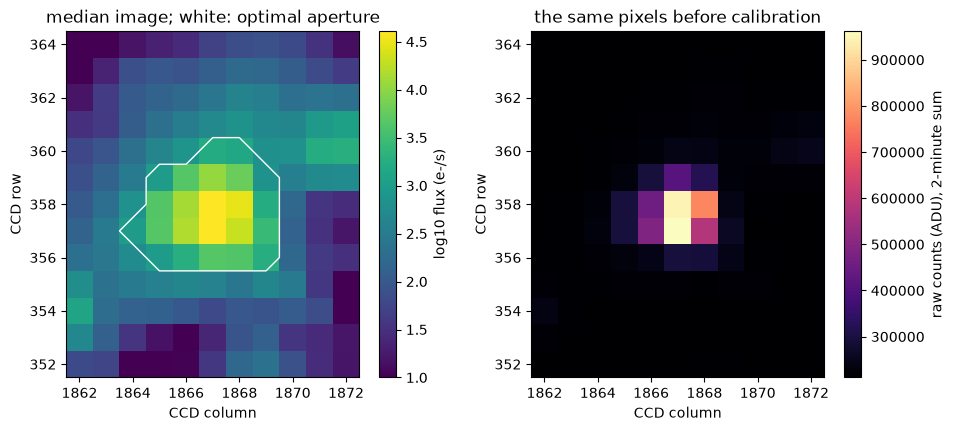

faintest median raw value: 211334 ADU = 4403 ADU per frame (48 frames kept per 2-minute sum), against about 41 ADU of sky per frame: mostly the electronic offset, plus sky and smear


In [31]:
img = px["flux"].median("time")
ap = (px["aperture"] & 2) > 0
fig, axs = plt.subplots(1, 2, figsize=(11, 4.5))
ext = [float(px["column"][0]) - 0.5, float(px["column"][-1]) + 0.5, float(px["row"][0]) - 0.5, float(px["row"][-1]) + 0.5]
im = axs[0].imshow(np.log10(np.clip(img, 10, None)), origin="lower", extent=ext, cmap="viridis")
axs[0].contour(px["column"].values, px["row"].values, ap.values.astype(int), levels=[0.5], colors="w", linewidths=1)
fig.colorbar(im, ax=axs[0], label="log10 flux (e-/s)")
axs[0].set_title("median image; white: optimal aperture")
im2 = axs[1].imshow(px["raw_cnts"].median("time"), origin="lower", extent=ext, cmap="magma")
fig.colorbar(im2, ax=axs[1], label="raw counts (ADU), 2-minute sum")
axs[1].set_title("the same pixels before calibration")
for ax in axs:
    ax.set_xlabel("CCD column")
    ax.set_ylabel("CCD row")
plt.show()
raw_min = float(px["raw_cnts"].median("time").min())
sky_adu = float(px["flux_bkg"].median()) * h1["INT_TIME"] / h1["GAINA"]   # sky per pixel per frame: e-/s x 1.98 s / gain (e-/ADU, header GAINA)
print(f"faintest median raw value: {raw_min:.0f} ADU = {raw_min / 48:.0f} ADU per frame (48 frames kept per 2-minute sum), "
      f"against about {sky_adu:.0f} ADU of sky per frame: mostly the electronic offset, plus sky and smear")

**Question 4b.** In which CCD row and column is the brightest pixel?

**Question 4c.** The cell subtracts the mean in-transit image from the mean out-of-transit image. Is the light missing on HD 209458 or on a neighbour? A faint eclipsing pair of stars nearby would put the deficit on the neighbour; this test helps reject false positives (Part 7).

not answered yet


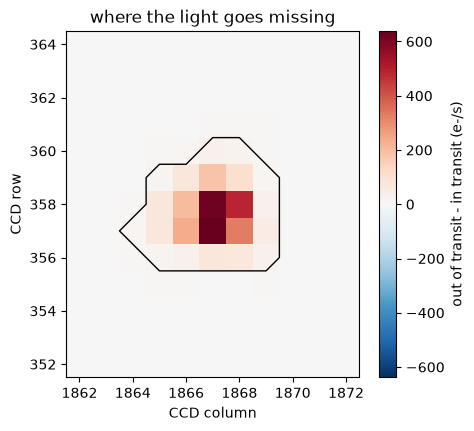

not answered yet


In [32]:
answer_4b = {"row": None, "column": None}
check("4b", answer_4b)

# Difference image: central half of the transit against the stretches before ingress and after egress.
ph = np.abs(ck.phase_days(px["time"].values, P, T0))
in_transit = ph < 0.25 * D            # central half of the transit
out_of_transit = ph > 0.75 * D        # before ingress and after egress
diff = px["flux"].isel(time=np.flatnonzero(out_of_transit)).mean("time") - px["flux"].isel(time=np.flatnonzero(in_transit)).mean("time")
plt.figure(figsize=(5, 4.5))
plt.imshow(diff, origin="lower", extent=ext, cmap="RdBu_r", vmin=-float(abs(diff).max()), vmax=float(abs(diff).max()))
plt.colorbar(label="out of transit - in transit (e-/s)")
plt.contour(px["column"].values, px["row"].values, ap.values.astype(int), levels=[0.5], colors="k", linewidths=1)
plt.xlabel("CCD column"); plt.ylabel("CCD row"); plt.title("where the light goes missing")
plt.show()

answer_4c = None   # a few words: where is the deficit?
check("4c", answer_4c)

In [33]:
# Worked solution, open after you tried
r, c = np.unravel_index(int(np.nanargmax(img.values)), img.shape)
print("4b: brightest pixel at row", int(px["row"][r]), "column", int(px["column"][c]))
r2, c2 = np.unravel_index(int(np.nanargmax(diff.values)), diff.shape)
print("4c: largest deficit at row", int(px["row"][r2]), "column", int(px["column"][c2]),
      f"| share of the deficit inside the aperture: {float(diff.where(ap).sum() / diff.sum()) * 100:.0f}%")
sap = px["flux"].where(ap).sum(("row", "column"))
print(f"    depth from summing the aperture pixels yourself: {float((sap[out_of_transit].mean() - sap[in_transit].mean()) / sap[out_of_transit].mean() * 1e6):.0f} ppm")
# The deficit sits on the target's brightest pixels and follows its light profile: the planet orbits HD 209458.

4b: brightest pixel at row 357 column 1867
4c: largest deficit at row 357 column 1867 | share of the deficit inside the aperture: 96%
    depth from summing the aperture pixels yourself: 15783 ppm


```{admonition} If you are stuck
:class: tip
- *A blank or saturated image:* the star is 1000 times brighter than the sky; keep the `np.log10(np.clip(...))` scaling.
- *Row and column come out as 0 to 12:* read `px['row'][r]` and `px['column'][c]`, not the index.
```

## Part 5. A synthetic twin with planted problems (15 min)

(a) List what can go wrong (2 min); (b) hunt (7 min); (c) depth and radius three ways (3 min); (d) reflect (3 min).

Unlike the real data, the twin has a known truth, so you can measure how much each problem biases the result. It copies the sector 56 cadences and documented gaps (quality 8, 32 or 128), the flux level and white noise of HD 209458 (not its slow variations), and the archive geometry of HD 209458 b with limb darkening fitted to the real transits. Its planet is `SYN-209458 b`; its star is a copy of HD 209458. A small table of measured planets comes with it. Problems that instruments, pipelines and catalogs produce are then planted, chosen by your NetID; the worked solutions use the class twin (empty NetID).

```{admonition} 🔒 By hand
:class: attention
No AI tool for the judgment in this step: state what you expect before you run anything, decide with a physical reason, and read the result against your expectation ([1.8](../Chapter1-GettingStarted/1.8_ai_in_your_workflow.md)).
```

**5a (2 min).** Before opening the twin, list at least four problems a space photometer, its processing or a compiled planet table could put in these files: think of the clock, pointing, stray light, detector, processing, catalog, and the star itself.

In [34]:
answer_5a = []      # e.g. ["...", "...", "...", "..."]
check("5a", answer_5a)

not answered yet


In [35]:
# Worked solution, open after you tried
print("""- clock: barycentric correction missing or applied twice; UTC instead of TDB; BJD instead of BTJD.
  It happened in sector 6: the clock kernel, extrapolated from old ranging data, put the times of all products
  off by about 2.0 s by the end of the sector (HEASARC TESS data release notes,
  https://heasarc.gsfc.nasa.gov/docs/tess/data_release_notes.html)
- pointing and sensitivity: sudden steps in the flux when the star shifts on the pixels or the detector response
  changes; SPOC marks the ones it corrects with quality bit 256
- stray light: Earth or Moon light raising the background for about a day, part of it left in the flux
- detector and data: single-value outliers (SPOC's 'impulsive outlier', bit 512); saturation and bleed columns
  for very bright stars
- processing: gaps filled with zeros, a sentinel value or the last good value repeated; duplicated rows;
  a unit change mid-record
- catalog: radius in Jupiter radii in an Earth-radius column; the same planet twice; computed values labelled measured
- the star: flares, spots, and a neighbour whose light leaks into the aperture""")

- clock: barycentric correction missing or applied twice; UTC instead of TDB; BJD instead of BTJD.
  It happened in sector 6: the clock kernel, extrapolated from old ranging data, put the times of all products
  off by about 2.0 s by the end of the sector (HEASARC TESS data release notes,
  https://heasarc.gsfc.nasa.gov/docs/tess/data_release_notes.html)
- pointing and sensitivity: sudden steps in the flux when the star shifts on the pixels or the detector response
  changes; SPOC marks the ones it corrects with quality bit 256
- stray light: Earth or Moon light raising the background for about a day, part of it left in the flux
- detector and data: single-value outliers (SPOC's 'impulsive outlier', bit 512); saturation and bleed columns
  for very bright stars
- processing: gaps filled with zeros, a sentinel value or the last good value repeated; duplicated rows;
  a unit change mid-record
- catalog: radius in Jupiter radii in an Earth-radius column; the same planet twice; computed va

In [36]:
twin = syn.make_twin(MY_NETID)
print(twin)
print("orbit of SYN-209458 b:", {k: round(twin.target[k], 5) for k in ("period_days", "t0_btjd", "duration_days")})
oot_real = lc["PDCSAP_FLUX"].notna() & (np.abs(ck.phase_days(lc["TIME"], P, T0)) > D)
rel_real = lc.loc[oot_real, "PDCSAP_FLUX"] / lc.loc[oot_real, "PDCSAP_FLUX"].median() - 1
print(f"twin noise: {twin.target['noise_ppm']:.0f} ppm of white noise per 2-minute value (median absolute deviation of the real "
      f"PDCSAP_FLUX outside transits). The real light curve also varies slowly: rms {rel_real.std() * 1e6:.0f} ppm, and "
      f"1-hour precision (header CDPP1_0) {h1['CDPP1_0']:.1f} ppm against {twin.target['noise_ppm'] / np.sqrt(30):.0f} ppm for white noise alone.")
lc5, cat5 = twin.lc, twin.catalog
display(lc5.head(3)); display(cat5.head(3))

Twin(netid='', light curve 20079 rows -> synthetic_tess_lightcurve_class.csv, catalog 204 rows -> synthetic_planets_class.csv, 7 planted problems)
orbit of SYN-209458 b: {'period_days': 3.52475, 't0_btjd': 2826.7799, 'duration_days': 0.12788}
twin noise: 357 ppm of white noise per 2-minute value (median absolute deviation of the real PDCSAP_FLUX outside transits). The real light curve also varies slowly: rms 373 ppm, and 1-hour precision (header CDPP1_0) 78.5 ppm against 65 ppm for white noise alone.


,time_btjd,cadenceno,flux,flux_err,background,quality
0,2825.257074,1150414,NaN,NaN,NaN,160
1,2825.258463,1150415,NaN,NaN,NaN,32
2,2825.259852,1150416,NaN,NaN,NaN,32


,pl_name,hostname,discoverymethod,disc_year,pl_orbper,pl_rade,pl_bmasse,pl_bmassprov,st_rad,st_teff,sy_dist
0,SYN-7389 b,SYN-7389,Transit,2026,1.80209,17.008,218.912,Mass,1.830,5891.0,745.14
1,SYN-4921 b,SYN-4921,Transit,2010,3.57747,12.569,680.524,Mass,1.003,5800.0,392.79
2,SYN-0066 b,SYN-0066,Transit,2011,6.79012,13.337,2738.280,Mass,2.048,6395.0,798.00


**5b (7 min). Hunt.** Look, then test each suspicion with a physical check (commented below the plot; `zoom` looks closer). Record *what* each problem is, *where* (a BTJD range, or planet names), and *why* it cannot be the star or the planet.

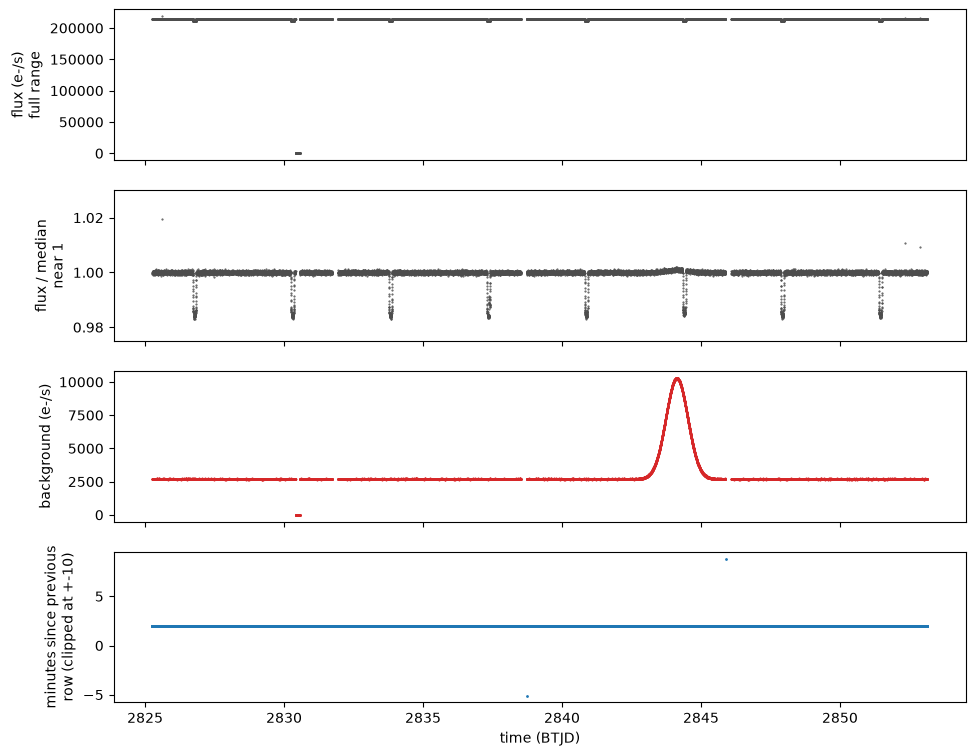

In [37]:
zoom = None                 # e.g. (2840.5, 2841.2) to look closer
f_med = lc5["flux"].median()
fig, axs = plt.subplots(4, 1, figsize=(11, 9), sharex=True)
axs[0].plot(lc5["time_btjd"], lc5["flux"], ".", ms=1, color="0.3"); axs[0].set_ylabel("flux (e-/s)\nfull range")
axs[1].plot(lc5["time_btjd"], lc5["flux"] / f_med, ".", ms=1, color="0.3"); axs[1].set_ylim(0.975, 1.03)
axs[1].set_ylabel("flux / median\nnear 1")
axs[2].plot(lc5["time_btjd"], lc5["background"], ".", ms=1, color="#d62728"); axs[2].set_ylabel("background (e-/s)")
axs[3].plot(lc5["time_btjd"].iloc[1:], np.clip(np.diff(lc5["time_btjd"]) * 1440, -10, 10), ".", ms=2, color="#1f77b4")
axs[3].set_ylabel("minutes since previous\nrow (clipped at +-10)"); axs[3].set_xlabel("time (BTJD)")
if zoom:
    axs[0].set_xlim(*zoom)
plt.show()

# Physical checks, one at a time (remove the # and run):
# lc5[lc5.duplicated("cadenceno", keep=False)]                       # the same cadence written twice?
# lc5[lc5["flux"] <= 0]                                              # a 7th-magnitude star giving no light?
# r = lc5["flux"].diff() == 0; lc5[r & r.shift(-1)]                  # the same value three times in a row: noise never does that
# syn.observed_minus_computed(lc5["time_btjd"], lc5["flux"], twin.target)   # does every transit arrive on schedule? (minutes)
# syn.depth_per_transit(lc5["time_btjd"], lc5["flux"], twin.target)  # one depth per transit: does one disagree?
# (lc5["flux"] - lc5["flux"].rolling(11, center=True).median()).nlargest(10)  # sudden brightenings: one cadence, or several?
# lc5.plot("time_btjd", "background")                                # does the sky rise and fall? does the flux follow it?
# (lc5["flux"].where(lc5["flux"] > 0).rolling(180, center=True, min_periods=60).median() / f_med).plot()   # slow changes: steps that persist, bumps that come back
# cat5.assign(rho=ck.bulk_density(cat5["pl_bmasse"], cat5["pl_rade"])).sort_values("rho").tail(10)   # densities no material allows
# cat5[cat5["pl_orbper"].round(4).duplicated(keep=False)].sort_values("pl_orbper")                 # one planet, two rows?
# cat5[np.isclose(cat5["pl_bmasse"], ck.chen_kipping_mass(cat5["pl_rade"]), rtol=1e-3)]          # masses exactly on the Chen & Kipping curve: computed or measured?

In [38]:
my_findings = [
    # {"what": "describe the problem", "start": 2830.10, "end": 2830.25, "why": "the physical reason"},   # light curve: BTJD
    # {"what": "describe the problem", "planets": ["SYN-0123 b"], "why": "the physical reason"},        # planet table rows
]
syn.score_findings(my_findings, twin)
# After you have tried, to see which kinds of problem you missed (not where they are):
# syn.score_findings(my_findings, twin, reveal=True)

not answered yet


In [39]:
# Worked solution, open after you tried
# Worked hunt on the class twin (empty NetID). Each block is one physical check; a check that finds nothing adds nothing.
tw = syn.make_twin("", outdir=tempfile.gettempdir())
L, C, g = tw.lc, tw.catalog, tw.target
found = []
d = L[L.duplicated("cadenceno", keep="first")]
if len(d):
    found.append({"what": "duplicated cadences", "start": d["time_btjd"].min(), "end": d["time_btjd"].max(),
                  "why": "a cadence number is measured once; time runs backwards at the end of the block"})
z = L[L["flux"] <= 0]
if len(z):
    found.append({"what": "gap filled with zeros, quality 0", "start": z["time_btjd"].min(), "end": z["time_btjd"].max(),
                  "why": "a 7th-magnitude star never gives zero light; a real gap is NaN with a quality flag"})
fl = L["flux"].to_numpy(); same = np.r_[False, fl[1:] == fl[:-1]] & (fl > 0)
runs = np.cumsum(~same); n_same = pd.Series(same).groupby(runs).transform("sum").to_numpy()
ff = L[(n_same >= 3) & pd.Series(runs).duplicated(keep=False).to_numpy()]
if len(ff):
    found.append({"what": "the last good value repeated (forward fill)", "start": ff["time_btjd"].min(), "end": ff["time_btjd"].max(),
                  "why": "photon noise never gives the same 7-digit value twice in a row"})
good = L["flux"].where(L["flux"] > 0)
base = good.rolling(11, center=True, min_periods=5).median()
res = (good - base) / base
idx = np.flatnonzero((res > 5 * 1.4826 * np.nanmedian(np.abs(res))).to_numpy())
for gi in np.split(idx, np.flatnonzero(np.diff(idx) > 3) + 1):
    if not len(gi):
        continue
    t_a, t_b = L["time_btjd"].iloc[gi[0]], L["time_btjd"].iloc[gi[-1]]
    if len(z) and (np.abs(z["time_btjd"] - t_a) < 0.01).any():
        print(f"{t_a:.3f}: next to the zero block, the running median is cut: not a problem of its own")
        continue
    near = np.abs(ck.phase_days(t_a, g["period_days"], g["t0_btjd"])) < g["duration_days"] / 2
    if len(gi) >= 2:
        print(f"{t_a:.3f}-{t_b:.3f}: {len(gi)} cadences, peak {res.iloc[gi].max() * 100:.2f}% above the running median"
              f"{', inside a transit' if near else ''}: a flare (fast rise, slower decay)")
        found.append({"what": "stellar flare: fast rise, slower decay", "start": t_a, "end": t_b + 0.02,
                      "why": "a real outburst of the star; keep it as real, but out of the depth"})
        # A flare this size is rare on an old, quiet star like HD 209458 and common on young stars and red dwarfs;
        # here it stands for real stellar activity that cleaning must not erase.
    else:
        print(f"{t_a:.3f}: one cadence, {res.iloc[gi].max() * 100:.1f}% bright: a single-value outlier")
        found.append({"what": "single-cadence outlier", "start": t_a, "end": t_b,
                      "why": "one 2-minute value about 1% bright, the next normal: no star brightens that fast"})
b = L["background"].where(L["background"] > 0)
hb = L[b > b.median() + 10 * 1.4826 * (b - b.median()).abs().median()]
if len(hb):
    print(f"background: median {b.median():.0f} e-/s, up to {b.max():.0f} e-/s between BTJD {hb['time_btjd'].min():.2f} and {hb['time_btjd'].max():.2f}")
    found.append({"what": "scattered light: background rises and falls, flux follows", "start": hb["time_btjd"].min(), "end": hb["time_btjd"].max(),
                  "why": "background rises to several times its usual level and falls within a day; flux follows it with the same shape"})
oot5 = (np.abs(ck.phase_days(L["time_btjd"], g["period_days"], g["t0_btjd"])) > 0.75 * g["duration_days"]) & (L["flux"] > 0)
s5 = L[oot5].drop_duplicates("cadenceno")
s5 = s5.assign(seg=np.cumsum(np.r_[0, np.diff(s5["cadenceno"].to_numpy()) > 30]))
jumps = []
for _, part in s5.groupby("seg"):                 # median of the next 90 values minus median of the previous 90
    x = part["flux"].to_numpy() / part["flux"].median()
    jumps += [(part["time_btjd"].iloc[i], np.median(x[i:i + 90]) - np.median(x[i - 90:i])) for i in range(90, len(x) - 90, 5)]
jumps = pd.DataFrame(jumps, columns=["t", "change"])
big = jumps.loc[jumps["change"].abs().idxmax()]
print(f"largest change of the out-of-transit level: {big['change'] * 1e6:+.0f} ppm at BTJD {big['t']:.2f}"
      + (" (a step, if it persists)" if abs(big["change"]) > 6e-4 else " (no step above 600 ppm)"))
if abs(big["change"]) > 6e-4:
    found.append({"what": "flux step", "start": big["t"], "end": big["t"] + 0.5, "why": "the level changes at once and stays"})
oc = syn.observed_minus_computed(L["time_btjd"], L["flux"], g)
print(oc.to_string())
late = oc[oc["shift_minutes"].abs() > 3]
if len(late):
    found.append({"what": f"transits {late['shift_minutes'].abs().median():.0f} minutes early in one stretch: time offset "
                          "(spacecraft time, no barycentric correction)",
                  "start": late["predicted_mid_btjd"].min() - 0.1, "end": late["predicted_mid_btjd"].max() + 0.1,
                  "why": "a planet on a circular orbit cannot change its schedule for one week"})
dup = C[C["pl_orbper"].round(4).duplicated(keep=False)].sort_values("pl_orbper")
print(dup[["pl_name", "pl_orbper", "pl_rade", "pl_bmasse", "st_rad", "disc_year"]].to_string())
if len(dup):
    found.append({"what": "same planet twice under two spellings", "planets": list(dup["pl_name"]), "why": "same host, same period to 4 decimals"})
onc = C[(C["pl_bmassprov"] == "Mass") & np.isclose(C["pl_bmasse"], ck.chen_kipping_mass(C["pl_rade"]), rtol=1e-3)]
if len(onc):
    found.append({"what": "masses labelled 'Mass' that sit exactly on the Chen & Kipping curve", "planets": list(onc["pl_name"]),
                  "why": "measured masses scatter; computed ones fall on the curve to rounding"})
dense = C[ck.bulk_density(C["pl_bmasse"], C["pl_rade"]) > 30]
if len(dense):
    found.append({"what": "radius in Jupiter radii", "planets": list(dense["pl_name"]), "why": "denser than any material"})
syn.score_findings(found, tw, reveal=True)

2825.602: one cadence, 1.9% bright: a single-value outlier
2837.381-2837.382: 2 cadences, peak 0.23% above the running median, inside a transit: a flare (fast rise, slower decay)
2852.332: one cadence, 1.1% bright: a single-value outlier
2852.879: one cadence, 0.9% bright: a single-value outlier
background: median 2702 e-/s, up to 10303 e-/s between BTJD 2843.03 and 2845.22


largest change of the out-of-transit level: -282 ppm at BTJD 2844.76 (no step above 600 ppm)


   predicted_mid_btjd  shift_minutes  n_points
0           2826.7799           0.00       276
1           2830.3047           0.00       216
2           2833.8294           0.00       276
3           2837.3541          -0.75       277
4           2840.8789          -7.25       276
5           2844.4036          -6.50       276
6           2847.9284           0.00       276
7           2851.4531           0.25       276
          pl_name  pl_orbper  pl_rade  pl_bmasse  st_rad  disc_year
125    SYN 5496 b   3.185640   16.022    631.887   1.387       2026
155    SYN-5496 b   3.185640   15.308    655.939   1.387       2026
29   SYN-209458 b   3.524749   15.688    232.016   1.190       2022
44    SYN-209458b   3.524749   15.946    198.932   1.055       2024
18     SYN-2653 b   5.139670    2.714      8.104   0.820       2025
162     SYN-2653b   5.139670    2.593      7.791   0.820       2026
166    SYN 1520 b  15.270000    1.943      4.108   1.548       2015
173    SYN-1520 b  15.270000    2

7

**5c (3 min). The derived quantity, three ways.** The recipe `syn.transit_depth` divides the flux by its median and subtracts the mean flux in the central half of each transit from the mean 0.75 to 1.5 durations on either side. The radius is $\sqrt{\text{depth}} \times R_\star \times 109.08$ (Earth radii per solar radius). Compare truth, file as given, and your cleaning (one line per decision, with its reason), using a stellar radius from `cat5`. The self-check passes when your depth is within 1.5% of the truth, no planted problem still moves it by more than 0.3%, and your stellar radius is right; its hints say what is still wrong, not where.

In [40]:
g = twin.target
truth = twin.truth_depth()
as_given = syn.transit_depth(lc5["time_btjd"], lc5["flux"], g["period_days"], g["t0_btjd"], g["duration_days"])

my_clean = lc5.copy()
# One decision per line, with its reason. Examples (replace with your own):
# my_clean = my_clean.drop_duplicates("cadenceno")                          # a cadence is measured once
# my_clean = my_clean[~my_clean["time_btjd"].between(2840.70, 2840.82)]     # example window, use yours
# display(syn.depth_per_transit(my_clean["time_btjd"], my_clean["flux"], g))   # one depth per transit: does one disagree?
cleaned = syn.transit_depth(my_clean["time_btjd"], my_clean["flux"], g["period_days"], g["t0_btjd"], g["duration_days"])
my_st_rad = None    # the stellar radius of SYN-209458 you take from cat5, in solar radii

table = pd.DataFrame({"depth_ppm": [truth["depth_ppm"], as_given["depth_ppm"], cleaned["depth_ppm"]]},
                     index=["truth (recipe on the twin before planting)", "file as given", "after my cleaning"])
table["radius_earth"] = [syn.planet_radius_earth(x, my_st_rad) if my_st_rad else np.nan for x in table["depth_ppm"]]
display(table.round(1))
syn.check_depth(my_clean, twin, my_st_rad)

,depth_ppm,radius_earth
truth (recipe on the twin before planting),15783.4,NaN
file as given,-38661.7,NaN
after my cleaning,-38661.7,NaN


not answered yet: my_clean is still the file as given


In [41]:
# Worked solution, open after you tried
# Class twin: a generic cleaning, every step with its reason.
gt = tw.target
depth3 = lambda t_, f_: syn.transit_depth(t_, f_, gt["period_days"], gt["t0_btjd"], gt["duration_days"])["depth_ppm"]
progress = {"file as given": depth3(tw.lc["time_btjd"], tw.lc["flux"])}   # the depth after each step (used in 5d)
c = tw.lc.drop_duplicates("cadenceno").copy()                         # a cadence is measured once
progress["duplicated cadences removed"] = depth3(c["time_btjd"], c["flux"])
c = c[~(c["flux"] <= 0)]                                              # zero light is a fill value, not the star
progress["+ zeros removed"] = depth3(c["time_btjd"], c["flux"])
f = c["flux"].to_numpy(); rep = np.r_[False, f[1:] == f[:-1]]         # forward fill: noise never repeats exactly
run = np.cumsum(~rep); n = pd.Series(rep).groupby(run).transform("sum").to_numpy()
c = c[~((n >= 2) & pd.Series(run).duplicated(keep=False).to_numpy())]
c = c[c["flux"].notna()].copy()
progress["+ repeated values removed"] = depth3(c["time_btjd"], c["flux"])
c["seg"] = np.cumsum(np.r_[0, np.diff(c["cadenceno"].to_numpy()) > 30])   # stretches between downlinks
for s_, part in c.groupby("seg"):                                     # put each stretch back on the orbit's clock
    oc_ = syn.observed_minus_computed(part["time_btjd"], part["flux"], gt)
    if len(oc_) and abs(oc_["shift_minutes"].median()) > 3:
        c.loc[part.index, "time_btjd"] = part["time_btjd"] - oc_["shift_minutes"].median() / 1440
progress["+ clock put back on the orbit"] = depth3(c["time_btjd"], c["flux"])
base = c["flux"].rolling(11, center=True, min_periods=5).median()    # outliers and flare: one-sided, brightenings only
res = (c["flux"] - base) / base
hot = np.convolve((res > 5 * 1.4826 * np.nanmedian(np.abs(res))).astype(int).to_numpy(), np.ones(7), mode="same") > 0
c = c[~hot].copy()
progress["+ outliers and flare removed"] = depth3(c["time_btjd"], c["flux"])
oot = np.abs(ck.phase_days(c["time_btjd"], gt["period_days"], gt["t0_btjd"])) > 0.75 * gt["duration_days"]
trend = pd.Series(np.where(oot, c["flux"], np.nan), index=c.index)   # scattered light and steps: divide by the local level
trend = trend.groupby(c["seg"]).transform(lambda s: s.rolling(181, center=True, min_periods=30).median().interpolate(limit_direction="both"))
c["flux"] = c["flux"] / trend
progress["+ divided by the local level"] = depth3(c["time_btjd"], c["flux"])
print(syn.depth_per_transit(c["time_btjd"], c["flux"], gt).to_string(index=False))   # no transit stands out
res3 = {"truth": tw.truth_depth()["depth_ppm"], "as given": depth3(tw.lc["time_btjd"], tw.lc["flux"]),
        "cleaned": depth3(c["time_btjd"], c["flux"])}
rows_t = tw.catalog[tw.catalog["hostname"].str.replace(" ", "-").str.startswith("SYN-209458")]
print(rows_t[["pl_name", "pl_rade", "st_rad", "disc_year"]].to_string(), "\n")
radii = sorted(rows_t["st_rad"].unique())
st_pick = min(radii, key=lambda r_: abs(r_ - hd["st_rad"]))           # the twin's star is a copy of HD 209458 (Part 0)
for k, v in res3.items():
    print(f"{k:>9}: depth {v:8.0f} ppm ({(v - res3['truth']) / res3['truth'] * 100:+6.1f}% from the truth) -> radius "
          + ", ".join(f"{syn.planet_radius_earth(v, r_):.2f} (R* = {r_})" for r_ in radii) + " Earth radii")
print(f"true radius: {tw.truth_radius():.2f} Earth radii (radius ratio {gt['rp_rs_true']:.5f} x {gt['st_rad_true']} solar radii)")
print(f"limb darkening: sqrt(depth) on the truth gives a radius {(syn.planet_radius_earth(res3['truth'], gt['st_rad_true']) / tw.truth_radius() - 1) * 100:.1f}% too large")
if len(radii) > 1:
    print(f"the two stellar radii move the planet radius by {(max(radii) / min(radii) - 1) * 100:.0f}%; "
          f"R* = {st_pick} is the one that matches HD 209458 in the archive")
syn.check_depth(c, tw, st_pick)
# The file as given gives a NEGATIVE depth: the zeros sit in the window around a transit and drag that mean far
# below the in-transit mean. The generic cleaning brings the depth within a few tenths of a percent of the truth.
# Even the truth recipe gives a radius a few percent too large: limb darkening makes the centre of the transit
# deeper than (Rp/R*)^2. The duplicated star row moves the radius by more than all light-curve problems together.

 mid_btjd  depth_ppm  n_in  n_around
 2826.780      15707    46       138
 2830.305      15765    46        78
 2833.829      15848    46       138
 2837.354      15851    39       138
 2840.879      15739    46       139
 2844.404      15886    46       138
 2847.928      15865    46       138
 2851.453      15746    46       138
         pl_name  pl_rade  st_rad  disc_year
29  SYN-209458 b   15.688   1.190       2022
44   SYN-209458b   15.946   1.055       2024 

    truth: depth    15783 ppm (  +0.0% from the truth) -> radius 14.46 (R* = 1.055), 16.31 (R* = 1.19) Earth radii
 as given: depth   -38662 ppm (-345.0% from the truth) -> radius nan (R* = 1.055), nan (R* = 1.19) Earth radii
  cleaned: depth    15801 ppm (  +0.1% from the truth) -> radius 14.47 (R* = 1.055), 16.32 (R* = 1.19) Earth radii
true radius: 15.69 Earth radii (radius ratio 0.12086 x 1.19 solar radii)
limb darkening: sqrt(depth) on the truth gives a radius 3.9% too large
the two stellar radii move the planet radius 

True

**5d (3 min). Reflect.** Which problems moved the depth, and by how much? Which barely mattered for the depth but would matter for another quantity (the period, the transit times)? Which can cleaning not undo, and why?

In [42]:
answer_5d = None    # a few sentences
check("5d", answer_5d)

not answered yet


In [43]:
# Worked solution, open after you tried
truth_d = res3["truth"]
for k, v in progress.items():
    print(f"{k:>34}: depth {v:8.0f} ppm, {(v - truth_d) / truth_d * 100:+7.2f}% from the truth")
flare = [p_ for p_ in tw._planted if p_["category"] == "flare"]
if flare:
    tf = flare[0]["t0"]
    print(f"the flare starts at BTJD {tf:.3f}, {ck.phase_days(tf, gt['period_days'], gt['t0_btjd']) * 24 * 60:+.0f} min from a mid-transit")
print("""
Class twin. The zero-filled block alone turned the depth negative: the recipe averages, so one bad block in the
window around a transit outweighs everything else. The single-value outliers fall outside the transit windows.
The flare sits inside a transit and fills part of the dip; removing its points moves the depth by about half a
percent and leaves that transit with fewer points. The time offset (7 minutes) barely moves the depth, because the
in-transit window is +-46 min, but it biases the transit times, the period and any study of timing variations.
The scattered light reaches the flux only through the background estimate, a few hundred ppm.
Cleaning cannot undo the cadences lost under the zeros (that light was never recorded), the transit under the
flare, or the duplicated star row: the files alone cannot say which stellar radius is right; the original papers
can, and the planet radius moves with that choice more than with all light-curve problems together. The time
offset can be undone only because a planet's orbit is a clock we trust.""")

                     file as given: depth   -38662 ppm, -344.95% from the truth
       duplicated cadences removed: depth   -38662 ppm, -344.95% from the truth
                   + zeros removed: depth    15692 ppm,   -0.58% from the truth
         + repeated values removed: depth    15692 ppm,   -0.58% from the truth
     + clock put back on the orbit: depth    15704 ppm,   -0.50% from the truth
      + outliers and flare removed: depth    15792 ppm,   +0.05% from the truth
      + divided by the local level: depth    15801 ppm,   +0.11% from the truth
the flare starts at BTJD 2837.379, +35 min from a mid-transit

Class twin. The zero-filled block alone turned the depth negative: the recipe averages, so one bad block in the
window around a transit outweighs everything else. The single-value outliers fall outside the transit windows.
The flare sits inside a transit and fills part of the dip; removing its points moves the depth by about half a
percent and leaves that transit with fewer 

```{admonition} If you are stuck
:class: tip
- *`score_findings` finds nothing you found:* give `start` and `end` as BTJD numbers, a window up to 3 days; for a step, its time as `start`; catalog rows as `"planets": [names]`, spelled as in `cat5`.
- *Your cleaned depth does not change:* every line must assign back to `my_clean`.
```

## Part 6. Correlations on the real data (8 min)

Expected sign (1 min), two correlations on two subsets (3 min), the plot and the trap (4 min).

```{admonition} 🔒 By hand
:class: attention
No AI tool for the judgment in this step: state what you expect before you run anything, decide with a physical reason, and read the result against your expectation ([1.8](../Chapter1-GettingStarted/1.8_ai_in_your_workflow.md)).
```

**Question 6a.** Over all planets, do you expect log mass and log radius to correlate positively, negatively, or not at all? Write `1`, `-1` or `0` before computing, with your physical reason in a comment.

In [44]:
answer_6a = None    # 1, 0 or -1
check("6a", answer_6a)

not answered yet


In [45]:
# Worked solution, open after you tried
print("""+1. Over the whole range, heavier bodies are larger: a rock of 5 Earth masses is bigger than one of 1, and a
gas giant of 300 Earth masses is far bigger than either. Caveat, shown below: above about 130 Earth masses (the
break in the Chen & Kipping relation) the radius stops growing, because electron degeneracy pressure holds up the
interior of a heavy giant and added mass barely changes its size.""")

+1. Over the whole range, heavier bodies are larger: a rock of 5 Earth masses is bigger than one of 1, and a
gas giant of 300 Earth masses is far bigger than either. Caveat, shown below: above about 130 Earth masses (the
break in the Chen & Kipping relation) the radius stops growing, because electron degeneracy pressure holds up the
interior of a heavy giant and added mass barely changes its size.


**Question 6b.** Compute the Pearson correlation of log10(mass) with log10(radius), and the Spearman rank correlation of mass with radius, for (i) all rows with both values above zero, and (ii) rows where both are measurements: `ck.measured_mass_and_radius(planets)` keeps transiting planets with a mass of provenance "Mass" and no limit flag.

In [46]:
all_rows = planets[(planets["pl_bmasse"] > 0) & (planets["pl_rade"] > 0)]
measured = ck.measured_mass_and_radius(planets)
print(len(all_rows), "rows with both values;", len(measured), "with both measured")
# Your computation: stats.pearsonr(...)[0], stats.spearmanr(...)[0]

answer_6b = {"pearson_all": None, "spearman_all": None, "pearson_measured": None, "spearman_measured": None}
check("6b", answer_6b)

6371 rows with both values; 1543 with both measured
not answered yet


In [47]:
# Worked solution, open after you tried
for name, s in [("all", all_rows), ("measured", measured)]:
    print(f"{name:>9}: n = {len(s)}, Pearson(log) = {stats.pearsonr(np.log10(s['pl_bmasse']), np.log10(s['pl_rade']))[0]:.3f}, "
          f"Spearman = {stats.spearmanr(s['pl_bmasse'], s['pl_rade'])[0]:.3f}, Pearson(linear) = {stats.pearsonr(s['pl_bmasse'], s['pl_rade'])[0]:.3f}")

      all: n = 6371, Pearson(log) = 0.917, Spearman = 0.930, Pearson(linear) = 0.452
 measured: n = 1543, Pearson(log) = 0.878, Spearman = 0.841, Pearson(linear) = 0.311


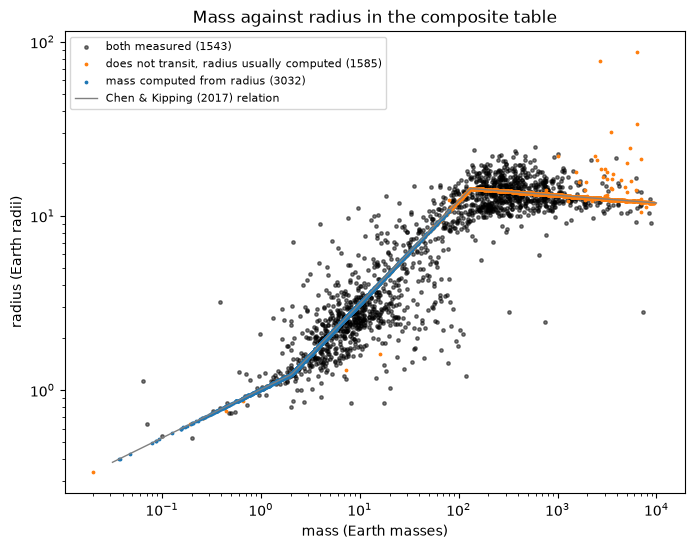

measured, 0-20 Earth masses: n = 586, Spearman = 0.65
measured, 20-130 Earth masses: n = 282, Spearman = 0.61
measured, 130-10000 Earth masses: n = 675, Spearman = -0.05
share of giants (> 8 Earth radii): 52% of 'both measured' rows, 19% of all transiting planets


In [48]:
calc_r = all_rows["tran_flag"] == 0                         # radius usually computed from the mass
calc_m = all_rows["pl_bmassprov"] == "M-R relationship"     # mass computed from the radius
m_grid = np.logspace(-1.5, 4, 300)
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(measured["pl_bmasse"], measured["pl_rade"], s=6, color="k", alpha=0.5, label=f"both measured ({len(measured)})")
ax.scatter(all_rows.loc[calc_r & ~calc_m, "pl_bmasse"], all_rows.loc[calc_r & ~calc_m, "pl_rade"], s=3, color="#ff7f0e", label=f"does not transit, radius usually computed ({(calc_r & ~calc_m).sum()})")
ax.scatter(all_rows.loc[calc_m, "pl_bmasse"], all_rows.loc[calc_m, "pl_rade"], s=3, color="#1f77b4", label=f"mass computed from radius ({calc_m.sum()})")
ax.plot(m_grid, ck.chen_kipping_radius(m_grid), color="0.5", lw=1, label="Chen & Kipping (2017) relation")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("mass (Earth masses)"); ax.set_ylabel("radius (Earth radii)")
ax.legend(fontsize=8); ax.set_title("Mass against radius in the composite table")
plt.show()
for lo, hi in [(0, 20), (20, 130), (130, 10000)]:
    s = measured[(measured["pl_bmasse"] >= lo) & (measured["pl_bmasse"] < hi)]
    print(f"measured, {lo}-{hi} Earth masses: n = {len(s)}, Spearman = {stats.spearmanr(s['pl_bmasse'], s['pl_rade'])[0]:.2f}")
print(f"share of giants (> 8 Earth radii): {(measured['pl_rade'] > 8).mean() * 100:.0f}% of 'both measured' rows, "
      f"{(planets.loc[planets['tran_flag'] == 1, 'pl_rade'] > 8).mean() * 100:.0f}% of all transiting planets")

**Question 6c. The trap.** Why is the correlation higher over all rows than over measured rows? What does the share of giants among measured rows say about which planets get a measured mass? What does the Spearman correlation over measured planets say about planets, and what not?

In [49]:
answer_6c = None    # a few sentences
check("6c", answer_6c)

not answered yet


In [50]:
# Worked solution, open after you tried
nt_r = planets[(planets["tran_flag"] == 0) & planets["pl_rade"].notna() & planets["pl_bmasse"].notna()]
on_ck = np.abs(ck.chen_kipping_radius(nt_r["pl_bmasse"]) / nt_r["pl_rade"] - 1) < 0.01
print(f"planets that do not transit but have a radius: {len(nt_r)}; {int((nt_r['pl_bmassprov'] == 'Msini').sum())} of them take it "
      f"from a minimum mass (Msini); {on_ck.mean() * 100:.0f}% of the {len(nt_r)} radii lie within 1% of the Chen & Kipping curve")
print("""Almost half the rows carry a value the archive computed from the other one with the Chen & Kipping relation.
Those points lie on a curve by construction: they raise the correlation and say nothing about planets.
Second trap, detection: the planets with both values measured are selected. Giants are about half of them but
a fifth of transiting planets, because a heavy planet gives a large radial-velocity signal and a bright star
allows the follow-up. Third: the relation is not one line. Below about 20 Earth masses radius grows with mass
(Spearman 0.65); above about 130 it barely depends on mass (Spearman near 0), because electron degeneracy
pressure holds up a heavy giant, and the scatter among giants comes mostly from heating by their star, which
inflates close-in giants. The radii of planets that do not transit are mostly computed from a minimum mass
(Msini) through the same formula (first line above).
So 0.84 says that, in this selected sample, heavier planets are larger in rank order. It does not say how radius
depends on mass at fixed composition, it does not hold among giants, and it cannot be extrapolated to the
planets telescopes rarely measure: small, long-period planets around faint stars.""")

planets that do not transit but have a radius: 1585; 879 of them take it from a minimum mass (Msini); 97% of the 1585 radii lie within 1% of the Chen & Kipping curve
Almost half the rows carry a value the archive computed from the other one with the Chen & Kipping relation.
Those points lie on a curve by construction: they raise the correlation and say nothing about planets.
Second trap, detection: the planets with both values measured are selected. Giants are about half of them but
a fifth of transiting planets, because a heavy planet gives a large radial-velocity signal and a bright star
allows the follow-up. Third: the relation is not one line. Below about 20 Earth masses radius grows with mass
(Spearman 0.65); above about 130 it barely depends on mass (Spearman near 0), because electron degeneracy
pressure holds up a heavy giant, and the scatter among giants comes mostly from heating by their star, which
inflates close-in giants. The radii of planets that do not transit are mostly 

```{admonition} If you are stuck
:class: tip
- *`ValueError` from `pearsonr`:* a NaN or a zero slipped in; use `all_rows` and `measured` as defined.
- *Spearman differs slightly from the self-check:* Spearman takes the raw columns, Pearson `np.log10` of both.
```

## Part 7. From data to a learning problem (10 min)

The chain (3 min), task and labels (1 min), label distribution (2 min), balancing (4 min).

Follow-up observers give each TOI a verdict, the TFOPWG disposition (TESS Follow-up Observing Program Working Group), defined in `prov["column_definitions"]["toi"]["tfopwg_disp"]`; a planet candidate (PC) or ambiguous candidate (APC) still awaits one. Published classifiers help rank and vet such signals ([Shallue & Vanderburg 2018](https://doi.org/10.3847/1538-3881/aa9e09) and ExoMiner, [Valizadegan et al. 2022](https://doi.org/10.3847/1538-4357/ac4399), for Kepler; [Yu et al. 2019](https://doi.org/10.3847/1538-3881/ab21d6) for TESS); a confirmed verdict still needs follow-up observations or statistical validation.

**7.1 The chain (3 min).** Write the ordered steps from the light curves and the TOI table to a training table, each with its reason: what you select; what you remove, flag, or keep as a real extreme; any resampling; how you split training and test sets so nothing leaks.

In [51]:
my_chain = [
    # "1. ... because ...",
]
check("7chain", my_chain)

not answered yet


In [52]:
# Worked solution, open after you tried
print("""1. Keep TOIs with a verdict (CP, KP, FP, FA); PC and APC have no label yet: they are where the model would be used.
2. Read each star's light curve (PDCSAP and SAP) and its quality flags; drop cadences with documented bad quality,
   and flag the PDC-excluded stretches instead of losing them silently.
3. Remove what cannot be the star (zeros, duplicated cadences, forward-filled values, single-value outliers); keep
   flares and transits, which are real; mask flares from depth measurements.
4. Fold on the TOI period and resample the folded curve to fixed bins (the input of published classifiers);
   compute features such as depth, duration, odd-even depth difference and the centroid shift of Part 4.
5. Split by star (all TOIs of one star in the same set), then by creation date (train on older TOIs, test on newer).
6. Only then balance the training set, and evaluate on an untouched test set.""")

1. Keep TOIs with a verdict (CP, KP, FP, FA); PC and APC have no label yet: they are where the model would be used.
2. Read each star's light curve (PDCSAP and SAP) and its quality flags; drop cadences with documented bad quality,
   and flag the PDC-excluded stretches instead of losing them silently.
3. Remove what cannot be the star (zeros, duplicated cadences, forward-filled values, single-value outliers); keep
   flares and transits, which are real; mask flares from depth measurements.
4. Fold on the TOI period and resample the folded curve to fixed bins (the input of published classifiers);
   compute features such as depth, duration, odd-even depth difference and the centroid shift of Part 4.
5. Split by star (all TOIs of one star in the same set), then by creation date (train on older TOIs, test on newer).
6. Only then balance the training set, and evaluate on an untouched test set.


**Question 7a.** Which task fits "is this TOI a planet?": regression, classification, detection, forecasting or clustering? `CP` and `KP` (confirmed and known planets) are *planet*; `FP` is an astrophysical false positive, such as an eclipsing pair of stars; `FA` is a false alarm, an instrumental or noise feature like those in your twin.

**Question 7b.** Among labelled TOIs, what percentage is planet, false positive, false alarm?

In [53]:
toi = ck.read_toi()
by_verdict = toi.groupby(toi["tfopwg_disp"].fillna("none"))
print(pd.DataFrame({"TOIs": by_verdict.size(), "median depth (ppm)": by_verdict["pl_trandep"].median().round(0),
                    "median radius (Earth radii)": by_verdict["pl_rade"].median().round(1),
                    "median TESS magnitude": by_verdict["st_tmag"].median().round(1)}).to_string())

answer_7a = None     # one word
check("7a", answer_7a)
answer_7b = {"planet": None, "false_positive": None, "false_alarm": None}     # percent
check("7b", answer_7b)

             TOIs  median depth (ppm)  median radius (Earth radii)  median TESS magnitude
tfopwg_disp                                                                              
APC           488              5380.0                         12.9                   11.6
CP            814              1764.0                          3.2                   10.5
FA            100              1184.0                          3.5                   10.3
FP           1314              2940.0                         10.0                   10.7
KP            606             10045.0                         12.9                   11.6
PC           4824              5342.0                         10.8                   12.4
none            2             10533.0                         13.6                   13.7
not answered yet
not answered yet


In [54]:
# Worked solution, open after you tried
lab = toi["tfopwg_disp"].map({"CP": "planet", "KP": "planet", "FP": "false_positive", "FA": "false_alarm"})
print((lab.value_counts(normalize=True) * 100).round(2).to_string())
toi["created"] = pd.to_datetime(toi["toi_created"])
for a, b in [("2018", "2023"), ("2023", "2027")]:
    s = toi[(toi["created"] >= a) & (toi["created"] < b)]
    l = lab[s.index].dropna()
    print(f"TOIs created {a} to {int(b) - 1}: {len(s)}, labelled {len(l)} ({len(l) / len(s) * 100:.0f}%), "
          + ", ".join(f"{k} {v:.1f}%" for k, v in (l.value_counts(normalize=True) * 100).items()))
print("stars with more than one TOI:", int((toi.groupby("tid").size() > 1).sum()))
# Classification with three classes; false alarms are the rare class (about 3.5%). Planets and false positives are
# close to even, but the mix drifts with time: newer TOIs are mostly unlabelled, and those labelled so far are more
# often planets. A random split would hide that drift.

tfopwg_disp
planet            50.11
false_positive    46.37
false_alarm        3.53
TOIs created 2018 to 2022: 6138, labelled 2528 (41%), planet 48.7%, false_positive 47.5%, false_alarm 3.8%
TOIs created 2023 to 2026: 2010, labelled 306 (15%), planet 61.8%, false_positive 37.3%, false_alarm 1.0%
stars with more than one TOI: 248


**Who gets a label.** (1) The TOI list remains after the TESS team's vetting rejected most instrumental signals ([Guerrero et al. 2021](https://doi.org/10.3847/1538-4365/abefe1)), so the false-alarm share is a rate after a first filter. (2) Known planets (KP) are mostly giants from ground surveys (compare their median radius with CP): merging them into "planet" teaches the model that deep means planet. (3) Labels come first for bright stars; the unlabelled candidates are fainter, unlike the stars the model learns from.

**Balancing.** With 3.5% false alarms, a classifier that never predicts one is right 96.5% of the time and useless for that class. Stratify the split, then use class weights or resampling **on the training set only**; resampling before the split puts copies of one false alarm in both sets and inflates the score. Balancing changes the base rate the model learns, so recalibrate its probabilities. Judge the rare class by recall, precision and the precision-recall curve, not accuracy.

For **regression** the problem is a skewed target: most transiting planets are small, so a model learns the rare giants poorly. Reweight by bins of the target, stratify the split by its quantiles, report the error per bin. Which surveys could detect which planets shapes this target (7d): reweighting toward rare bins fits the mix of surveys behind the catalog, not the planets in nature. Decide which your model should represent.

In [55]:
# A split by star, then class weights computed on the training set only.
lab = toi["tfopwg_disp"].map({"CP": "planet", "KP": "planet", "FP": "false_positive", "FA": "false_alarm"})
labelled = toi[lab.notna()].assign(label=lab[lab.notna()])
rng = np.random.default_rng(469)
stars = labelled["tid"].unique()
test_stars = set(rng.choice(stars, size=len(stars) // 5, replace=False))
is_test = labelled["tid"].isin(test_stars)
train, test = labelled[~is_test], labelled[is_test]
counts = train["label"].value_counts()
weights = len(train) / (len(counts) * counts)            # class weight = N / (K x N_class)
print(pd.DataFrame({"train": train["label"].value_counts(), "test": test["label"].value_counts(), "weight": weights.round(2)}))
print("weighted share of each class in training:", (counts * weights / (counts * weights).sum()).round(3).to_dict())

answer_7c = {"balance_before_split": None, "metric": None}     # True or False; a metric name for the rare class
check("7c", answer_7c)

                train  test  weight
label                              
false_alarm        78    22    9.70
false_positive   1036   278    0.73
planet           1155   265    0.65
weighted share of each class in training: {'planet': 0.333, 'false_positive': 0.333, 'false_alarm': 0.333}
not answered yet


In [56]:
# Worked solution, open after you tried
print({"balance_before_split": False, "metric": "recall and precision of the false-alarm class (precision-recall curve)"})
# With the weights, each class counts one third in the loss: the model learns a world where false alarms are as
# common as planets. Its probabilities must be corrected back to the real base rate (3.5%) before use.

{'balance_before_split': False, 'metric': 'recall and precision of the false-alarm class (precision-recall curve)'}


**Question 7d. A regression target.** For transiting planets with a radius (`tran_flag == 1`, `pl_radelim == 0`), compute the median radius, the 90th percentile, and the percentage above 8 Earth radii. From the histogram and the facilities below it: where would a model have few examples, and who found the rare planets?

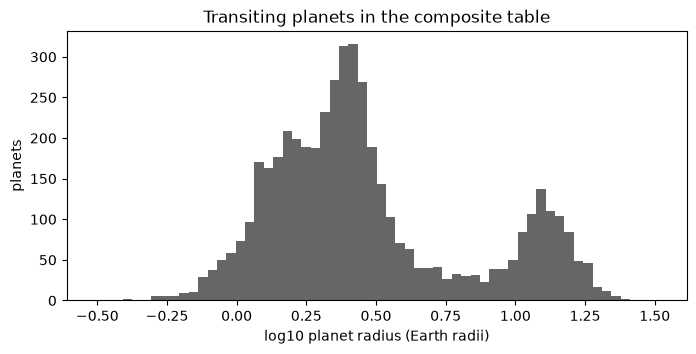

share found by Kepler: 57% of these planets, 13% of those above 8 Earth radii
who found the planets above 8 Earth radii: {'Transiting Exoplanet Survey Satellite (TESS)': 307, 'SuperWASP': 119, 'Kepler': 117, 'HATSouth': 68, 'HATNet': 65}
not answered yet


In [57]:
radius = planets.loc[(planets["tran_flag"] == 1) & (planets["pl_radelim"] == 0), "pl_rade"].dropna()
plt.figure(figsize=(8, 3.5))
plt.hist(np.log10(radius), bins=60, color="0.4")
plt.xlabel("log10 planet radius (Earth radii)"); plt.ylabel("planets"); plt.title("Transiting planets in the composite table")
plt.show()
fac = planets.loc[radius.index, "disc_facility"]
print(f"share found by Kepler: {(fac == 'Kepler').mean() * 100:.0f}% of these planets, {(fac[radius > 8] == 'Kepler').mean() * 100:.0f}% of those above 8 Earth radii")
print("who found the planets above 8 Earth radii:", fac[radius > 8].value_counts().head(5).to_dict())

answer_7d = {"median": None, "p90": None, "pct_above_8": None}   # Earth radii; Earth radii; percent
check("7d", answer_7d)

In [58]:
# Worked solution, open after you tried
q = radius.quantile([0.25, 0.5, 0.75, 0.9])
print(f"n = {len(radius)}, median {radius.median():.2f}, 90th percentile {radius.quantile(0.9):.2f}, above 8: {(radius > 8).mean() * 100:.1f}%, skewness {stats.skew(radius):.2f}")
bins = pd.qcut(radius, 4)
print("quartile bins:", bins.cat.categories.astype(str).tolist())
edges = np.array([0, 1.5, 4, 8, 40])
w = pd.cut(radius, edges).value_counts(sort=False)
print("weights inversely proportional to the count in each size bin:", (len(radius) / (len(w) * w)).round(2).to_dict())
# Two peaks: small planets (1 to 4 Earth radii, with the radius valley near 1.5-2: Fulton et al. 2017,
# doi:10.3847/1538-3881/aa80eb) and giants near 11-16. Few examples between 4 and 8 Earth radii, and the largest
# radii are rare. Kepler found more than half of these planets but few giants, which come mostly from TESS and
# ground surveys (SuperWASP, HATNet, HATSouth): reweighting toward giants weights what those surveys could detect.

n = 4807, median 2.46, 90th percentile 12.44, above 8: 18.5%, skewness 1.79
quartile bins: ['(0.309, 1.64]', '(1.64, 2.46]', '(2.46, 4.085]', '(4.085, 32.6]']
weights inversely proportional to the count in each size bin: {Interval(0.0, 1.5, closed='right'): 1.25, Interval(1.5, 4.0, closed='right'): 0.46, Interval(4.0, 8.0, closed='right'): 3.65, Interval(8.0, 40.0, closed='right'): 1.35}


```{admonition} If you are stuck
:class: tip
- *7b says not yet:* drop the PC, APC and empty rows before computing percentages; merge CP and KP.
- *A class is missing from the test set:* 100 false alarms leave about 20 in a 20% split by star; try another seed to see how unstable rare-class numbers are.
```

## Part 8. Check an AI tool on your twin (7 min, *if you have time*)

```{admonition} 🔍 Agent, then verify
:class: important
An AI tool does this step. You accept its result only after your own checks pass, and you record the conversation in `ai_conversation.md` (template in `lab_s07_templates/`; [1.8](../Chapter1-GettingStarted/1.8_ai_in_your_workflow.md)).
```

The twin test stays in this notebook (`ai_findings`, `answer_8`); item (d) is a separate conversation on the real data with your two files. Give an AI tool (UW Purple, Claude, or GitHub Copilot in VS Code) your two twin files and the instructions printed below. Decide your checks first: does it find your problems, invent others, remove the transits or the flare as outliers? Copy its findings into `ai_findings` as in `my_findings`.

In [59]:
print("files to give the AI tool:", twin.lc_path, twin.catalog_path, sep="\n  ")
print("\n" + syn.ai_instructions(twin))

files to give the AI tool:
  /var/folders/js/lzmy975n0l5bjbmr9db291m00000gn/T/mlgeo_s07_planetary/synthetic_tess_lightcurve_class.csv
  /var/folders/js/lzmy975n0l5bjbmr9db291m00000gn/T/mlgeo_s07_planetary/synthetic_planets_class.csv

I attach two CSV files from a synthetic copy of a NASA TESS light curve and of a planet table.

File 1, synthetic_tess_lightcurve_class.csv: one row per 2-minute cadence of a Sun-like star with a transiting giant planet.
Columns: time_btjd (Barycentric TESS Julian Date, BJD - 2457000, days), cadenceno (cadence counter),
flux and flux_err (electrons per second, simple aperture photometry), background (electrons per second,
already subtracted from flux), quality (bit flags: 8 = spacecraft pointed at Earth for data downlink,
32 = momentum dump, 128 = manual exclude; rows with these flags have no flux on purpose).

File 2, synthetic_planets_class.csv: one row per planet. Columns as in the NASA Exoplanet Archive composite table:
pl_rade (planet radius, Earth ra

In [60]:
ai_findings = [
    # each problem the AI tool reports, in the same format as my_findings
]
syn.score_findings(ai_findings, twin, who="the AI tool")
answer_8 = None             # what did it miss or invent? did it remove a transit or the flare as an outlier?
check("8", answer_8)

not answered yet
not answered yet


In [61]:
# Worked solution, open after you tried
print("""What to check in its answer (these instructions were not run on an AI tool when the notebook was written,
so these are failure modes to test for, not measured results):
- zeros and duplicated rows are easy: did it find them, and say where?
- a symmetric sigma-clip removes in-transit points, the largest real excursions in the file, and makes the depth
  too small: compare its number of in-transit points with yours;
- did it call the flare an error, or a real outburst of the star?
- did it test the clock against the orbit, or miss the time offset?
- in the table, did it compute densities, or compare masses with the Chen & Kipping curve?
Score its findings with the same function as yours; syn.check_ai_depth(depth, twin) compares its depth with the truth.""")

What to check in its answer (these instructions were not run on an AI tool when the notebook was written,
so these are failure modes to test for, not measured results):
- zeros and duplicated rows are easy: did it find them, and say where?
- a symmetric sigma-clip removes in-transit points, the largest real excursions in the file, and makes the depth
  too small: compare its number of in-transit points with yours;
- did it call the flare an error, or a real outburst of the star?
- did it test the clock against the orbit, or miss the time offset?
- in the table, did it compute densities, or compare masses with the Chen & Kipping curve?
Score its findings with the same function as yours; syn.check_ai_depth(depth, twin) compares its depth with the truth.


**After class: instructions for an AI tool.** Templates with hints for this track are in `lab_s07_templates/`.

- `reproducibility_rules.md`: rules an AI tool must follow on your project data, built on the six AGENTS.md headings of HW1 ([1.9](../Chapter1-GettingStarted/1.9_workbench_setup_hw1.md), Step 7) and the class rubric, each checkable yes or no.
- `pipeline_instructions.md`: from the raw file to the derived quantity. Here: get the sector 56 light curve from MAST; confirm it is unchanged (size, rows, SHA-256 in `snapshots/exoplanets_hd209458_tess_s56.provenance.json`); remove the documented gaps, flag the PDC-excluded stretch, keep transits and flares as real (flares masked from the depth); compute depth and radius with a stated stellar radius and its source; report what it could not do.
- `ai_conversation.md` (the transcript may be a PDF beside it): try both files on the real data with an AI tool and record what you checked and corrected. UW Purple cannot run code or read FITS files: give it the two `.md` files and the CSV written below. The cell below also prints the real-data depth and radius to compare the tool's numbers with.

In [62]:
lc_csv = ck.output_dir() / "hd209458_tess_s56_lightcurve.csv"
lc[["TIME", "TIMECORR", "CADENCENO", "SAP_FLUX", "SAP_FLUX_ERR", "SAP_BKG", "PDCSAP_FLUX", "PDCSAP_FLUX_ERR", "QUALITY"]].to_csv(lc_csv, index=False)
print(f"light curve as CSV, for a tool that cannot read FITS: {lc_csv} ({lc_csv.stat().st_size / 1e6:.1f} MB, {len(lc)} rows)")
# Reference values on the real light curve, for pipeline_instructions.md and ai_conversation.md (not the twin of Part 5).
# Removing the cadences with a QUALITY flag set changes neither value: in sector 56 no flagged cadence falls in
# or around a transit.
for label in ("SAP_FLUX", "PDCSAP_FLUX"):
    d_ = syn.transit_depth(lc["TIME"], lc[label], P, T0, D)["depth_ppm"]
    print(f"real data, {label} as read: depth {d_:.0f} ppm, radius {syn.planet_radius_earth(d_, hd['st_rad']):.2f} Earth radii "
          f"(stellar radius {hd['st_rad']} solar radii, from the planet table)")

light curve as CSV, for a tool that cannot read FITS: /var/folders/js/lzmy975n0l5bjbmr9db291m00000gn/T/mlgeo_s07_planetary/hd209458_tess_s56_lightcurve.csv (1.8 MB, 20079 rows)


real data, SAP_FLUX as read: depth 15728 ppm, radius 16.28 Earth radii (stellar radius 1.19 solar radii, from the planet table)
real data, PDCSAP_FLUX as read: depth 15753 ppm, radius 16.29 Earth radii (stellar radius 1.19 solar radii, from the planet table)


```{admonition} If you are stuck
:class: tip
- *The AI tool cannot read the files:* paste the first 200 lines of each CSV and tell it that it sees part of the light curve.
- *Its findings score 0:* copy its time ranges as BTJD numbers, not dates or row numbers.
```

## Wrap-up (3 min)

Three answers, two to four sentences each, each with one number or date from today's work, and its physical reason:

1. Your best radius for HD 209458 b from the TESS light curve: what limits it more, the light-curve problems or the star?
2. One pattern in planet tables that comes from what telescopes can detect rather than from the planets.
3. One step of the Part 7 chain you would do differently for your own project, and why.

Then run the summary cell.

**Submit on Canvas** ("Session 7: explore your system's data", Friday 16 October, 9:00 Pacific): this notebook as `.ipynb` (HTML optional), `reproducibility_rules.md`, `pipeline_instructions.md`, `ai_conversation.md` (the transcript may be a PDF beside it), and a two- or three-sentence comment on the exchange with the AI tool. Completion only: the work does not count toward your grade, but a missing submission costs 10 points.

In [63]:
wrap_1 = None
wrap_2 = None
wrap_3 = None
for a in (wrap_1, wrap_2, wrap_3):
    check("wrap", a)

not answered yet
not answered yet
not answered yet


In [64]:
# Worked solution, open after you tried
d_real = syn.transit_depth(lc["TIME"], lc["PDCSAP_FLUX"], P, T0, D)
print(f"1. Real PDCSAP depth with the Part 5 recipe: {d_real['depth_ppm']:.0f} ppm -> {syn.planet_radius_earth(d_real['depth_ppm'], hd['st_rad']):.2f} Earth radii "
      f"with R* = {hd['st_rad']} solar radii; the archive's radius ratio gives {hd['pl_ratror'] * hd['st_rad'] * ck.R_SUN_IN_R_EARTH:.2f}, and its pl_rade is {hd['pl_rade']:.2f}.")
print("   sqrt(depth) overestimates the radius by a few percent (limb darkening); the stellar radius enters linearly,")
print("   and the archive row mixes references. The star limits the answer more than the light curve does.")
print("2. Giants are about half of the planets with a measured mass and radius, but a fifth of transiting planets (Part 6);")
print("   the Kepler field is a clump on the sky because a telescope looked there (Part 0).")
print("3. For example: split by star and by time before any balancing, and keep the flags of the PDC-excluded stretches.")

1. Real PDCSAP depth with the Part 5 recipe: 15753 ppm -> 16.29 Earth radii with R* = 1.19 solar radii; the archive's radius ratio gives 15.69, and its pl_rade is 15.58.
   sqrt(depth) overestimates the radius by a few percent (limb darkening); the stellar radius enters linearly,
   and the archive row mixes references. The star limits the answer more than the light curve does.
2. Giants are about half of the planets with a measured mass and radius, but a fifth of transiting planets (Part 6);
   the Kepler field is a clump on the sky because a telescope looked there (Part 0).
3. For example: split by star and by time before any balancing, and keep the flags of the PDC-excluded stretches.


In [65]:
# Summary for Canvas: run this cell last and keep its output in the notebook you upload.
ck.print_summary(globals())

==== SESSION 7 SUMMARY ====
track: planetary
netid: not answered
parts answered: P0 0/1 | P1 0/4 | P2 0/5 | P3 0/4 | P4 0/3 | P5 0/4 | P6 0/3 | P7 0/5 | P8 0/2
self-checks passed: 0 of 32
planted problems found: not answered (seed 192391161686033)
derived quantity (truth / as given / after cleaning): 15783 / -38662 / not answered ppm
reflection 1: not answered
reflection 2: not answered
reflection 3: not answered
==== END SUMMARY ====
